# Лабораторная работа №2. Виртуальный датчик концентрации

В этой работе оцениваем концентрацию продукта в печи в текущую минуту. Для этого берём показания датчиков до этой минуты включительно и результаты проб, которые оператор уже получил. Лабораторные значения есть только в моменты отбора проб, поэтому по ним проверяем точность. Между замерами тоже строим прогноз, но сравнить его с фактом там нельзя.

| Пункт задания | Что проверяем |
|---|---|
| 2.1. Разведочный анализ | Пропуски, выбросы, сезонность, частота проб и связь телеметрии с таргетом |
| 2.2. Инжиниринг признаков | Лаги, скользящие окна, доступность данных и PCA |
| 2.3. Построение моделей | Бейзлайны, ARX, LightGBM и GRU |
| 2.3. Оценка качества | Ошибки, направление изменений, остатки, важность признаков и скорость |
| 2.4. Итоговые выводы | Что получилось на валидации и на тесте |

## 0. Настройки, импорты и загрузка данных

In [ ]:
import copy
import hashlib
import json
import math
from pathlib import Path
import time

from IPython import get_ipython
import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import scipy.special as special
import seaborn as sns
import shap
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
import torch
from torch import nn


SEED = 42
DATA_DIR = Path('data')
OUT_DIR = Path('results/revised')
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = dict(tele_train='data_train.csv', tgt_train='target_train.csv',
             tele_test='data_test_small.csv', tgt_test='target_test_small.csv')
TELE_TIME_COL, TGT_TIME_COL, TGT_COL = 'datetime', 'Дата', 'target'
LAB_TS_IS_RESULT_TIME = False
LAB_DELAY_MIN = 12
MAX_FFILL_MIN = 15
LAGS = [1, 5, 15, 30, 60, 120]
WINDOWS = [5, 15, 30, 60, 120, 360]
DIFFS = [5, 15, 60]
EWM_SPANS = (10, 60)
USE_TIME_FEATURES = False
GAP_MIN = 360
plt.rcParams.update({'figure.dpi': 105, 'axes.grid': True, 'grid.alpha': 0.22})
pd.options.display.float_format = '{:.4f}'.format

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
import warnings


In [2]:
def to_datetime_safe(s: pd.Series) -> pd.Series:
    """Приводит колонку к datetime: строки, unix-время в секундах/миллисекундах."""
    if pd.api.types.is_datetime64_any_dtype(s):
        t = s
    elif pd.api.types.is_numeric_dtype(s):
        unit = 'ms' if s.dropna().median() > 1e11 else 's'
        t = pd.to_datetime(s, unit=unit, errors='coerce')
    else:
        t = pd.to_datetime(s, errors='coerce')
    if getattr(t.dt, 'tz', None) is not None:
        t = t.dt.tz_localize(None)
    return t


def find_time_col(df: pd.DataFrame, preferred=None):
    """Ищет колонку времени: сначала по «говорящим» именам, затем по способности распарситься."""
    if preferred is not None:
        return preferred
    hints = ('time', 'date', 'ts', 'stamp', 'дата', 'время')
    cands = [c for c in df.columns if any(h in str(c).lower() for h in hints)]
    cands += [c for c in df.columns if c not in cands]
    for c in cands:
        s = df[c]
        if pd.api.types.is_numeric_dtype(s):
            if any(h in str(c).lower() for h in hints) and s.dropna().median() > 1e8:
                return c
            continue
        if pd.to_datetime(s, errors='coerce').notna().mean() > 0.95:
            return c
    raise ValueError('Не удалось найти колонку времени: задайте TELE_TIME_COL / TGT_TIME_COL вручную. '
                     f'Колонки файла: {list(df.columns)}')


def load_csv(path: Path, time_col=None, dup='first'):
    """Читает CSV -> DataFrame с DatetimeIndex (округлён до минуты, отсортирован, без дублей)."""
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.astype(str).str.startswith('Unnamed')]      # служебные индексные колонки
    tc = find_time_col(df, time_col)
    t = to_datetime_safe(df[tc])
    df = df.drop(columns=tc)
    df.index = pd.DatetimeIndex(t, name='time').floor('min')
    df = df[df.index.notna()].sort_index()
    df = df.apply(pd.to_numeric, errors='coerce')                          # нечисловое -> NaN
    n_dup = int(df.index.duplicated().sum())
    df = df.groupby(level=0).first() if dup == 'first' else df.groupby(level=0).mean()
    return df, tc, n_dup


tele_raw_tr, tc1, d1 = load_csv(DATA_DIR / FILES['tele_train'], TELE_TIME_COL, 'first')
tele_raw_te, tc2, d2 = load_csv(DATA_DIR / FILES['tele_test'], TELE_TIME_COL, 'first')
tgt_tr_df, tc3, d3 = load_csv(DATA_DIR / FILES['tgt_train'], TGT_TIME_COL, 'mean')
tgt_te_df, tc4, d4 = load_csv(DATA_DIR / FILES['tgt_test'], TGT_TIME_COL, 'mean')

# целевая колонка
if TGT_COL is None:
    assert tgt_tr_df.shape[1] == 1, f'В файле цели несколько колонок {list(tgt_tr_df.columns)} — задайте TGT_COL'
    TGT_COL = tgt_tr_df.columns[0]
y_raw_tr, y_raw_te = tgt_tr_df[TGT_COL].dropna(), tgt_te_df[TGT_COL].dropna()

SENSORS = list(tele_raw_tr.columns)
assert list(tele_raw_te.columns) == SENSORS, 'Набор колонок телеметрии в train и test различается'
print(f'Колонка времени телеметрии: {tc1!r}, цели: {tc3!r}; целевая колонка: {TGT_COL!r}')
print(f'Датчиков: {len(SENSORS)} -> {SENSORS}')
print(f'Телеметрия train: {tele_raw_tr.shape}, {tele_raw_tr.index.min()} .. {tele_raw_tr.index.max()} (дублей меток: {d1})')
print(f'Телеметрия test : {tele_raw_te.shape}, {tele_raw_te.index.min()} .. {tele_raw_te.index.max()} (дублей меток: {d2})')
print(f'Лаборатория train: {len(y_raw_tr)} замеров, {y_raw_tr.index.min()} .. {y_raw_tr.index.max()}')
print(f'Лаборатория test : {len(y_raw_te)} замеров, {y_raw_te.index.min()} .. {y_raw_te.index.max()}')

Колонка времени телеметрии: 'datetime', цели: 'Дата'; целевая колонка: 'target'
Датчиков: 16 -> ['telemetry_0', 'telemetry_1', 'telemetry_2', 'telemetry_3', 'telemetry_4', 'telemetry_5', 'telemetry_6', 'telemetry_7', 'telemetry_8', 'telemetry_9', 'telemetry_10', 'telemetry_11', 'telemetry_12', 'telemetry_13', 'telemetry_14', 'telemetry_15']
Телеметрия train: (317998, 16), 2019-03-01 00:01:00 .. 2019-10-07 19:58:00 (дублей меток: 1548)
Телеметрия test : (39747, 16), 2019-10-07 19:59:00 .. 2019-11-04 10:25:00 (дублей меток: 196)
Лаборатория train: 1773 замеров, 2019-03-13 17:00:00 .. 2019-10-07 21:00:00
Лаборатория test : 318 замеров, 2019-10-07 23:00:00 .. 2019-11-04 09:00:00


## 2.1. Разведочный анализ данных (EDA)

Для начала посмотрим на минутную телеметрию отдельно от каналов, которые обновляются редко. Если у телеметрии несколько записей за одну минуту, берём первое непустое значение каждого канала. Если совпадают метки лабораторных проб, усредняем их значения.

### 2.1.1. Телеметрия. Покрытие и пропуски

In [3]:
def to_full_grid(df):
    return df.reindex(pd.date_range(df.index.min(), df.index.max(), freq='min', name='time'))

tele_grid_tr = to_full_grid(tele_raw_tr)
tele_grid_te = to_full_grid(tele_raw_te)
SPARSE = tele_grid_tr.columns[tele_grid_tr.notna().mean() < 0.05].tolist()
DENSE = [c for c in SENSORS if c not in SPARSE]
earlier = tele_grid_tr.index < tele_grid_tr.index.max() - pd.Timedelta(days=21)
flat_thr = 0.01 * tele_grid_tr.loc[earlier, DENSE].std()
flat = tele_grid_tr[DENSE].rolling(360, min_periods=360).std() < flat_thr
overview = pd.DataFrame({
    'NaN train, %': tele_grid_tr.isna().mean() * 100,
    'Индекс Тьюки: за 3 IQR, %': (
        (tele_grid_tr.lt(tele_grid_tr.quantile(.25) - 3 * (tele_grid_tr.quantile(.75) - tele_grid_tr.quantile(.25))) |
         tele_grid_tr.gt(tele_grid_tr.quantile(.75) + 3 * (tele_grid_tr.quantile(.75) - tele_grid_tr.quantile(.25)))).sum()
        / tele_grid_tr.count() * 100
    ),
    'Плоские окна раньше': flat.loc[earlier].mean(),
    'Плоские окна в конце': flat.loc[~earlier].mean(),
})
FROZEN = flat.columns[(flat.loc[~earlier].mean() > .9) & (flat.loc[earlier].mean() < .5)].tolist()
ACTIVE = [c for c in DENSE if c not in FROZEN]
print(f'Минут без строки в train: {len(tele_grid_tr) - len(tele_raw_tr)}')
print('Редкие каналы:', SPARSE, '| Недоступны после залипания в конце train:', FROZEN)
display(overview)

Минут без строки в train: 0
Редкие каналы: ['telemetry_12', 'telemetry_13', 'telemetry_14', 'telemetry_15'] | Недоступны после залипания в конце train: ['telemetry_9', 'telemetry_10', 'telemetry_11']


,"NaN train, %","Индекс Тьюки: за 3 IQR, %",Плоские окна раньше,Плоские окна в конце
telemetry_0,0.0053,20.2805,0.1336,0.0248
telemetry_1,0.0050,21.4179,0.4214,0.1982
telemetry_10,0.0050,0.0000,0.1897,0.9879
telemetry_11,0.0050,0.0000,0.2332,0.9760
telemetry_12,99.3406,0.0000,NaN,NaN
telemetry_13,99.3406,0.0000,NaN,NaN
telemetry_14,99.3406,0.0954,NaN,NaN
telemetry_15,99.3406,0.0000,NaN,NaN
telemetry_2,0.0050,19.3215,0.0361,0.0000
telemetry_3,0.0050,19.8505,0.1761,0.1314


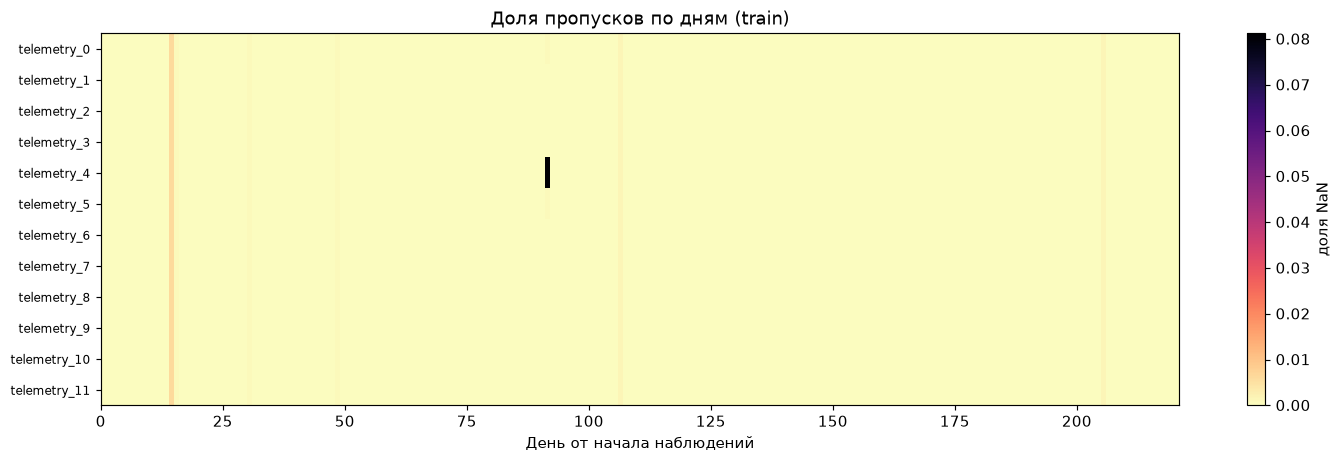

In [4]:
daily_miss = tele_grid_tr[DENSE].isna().resample('1D').mean().T
fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(daily_miss.values, aspect='auto', cmap='magma_r', vmin=0, vmax=max(float(daily_miss.max().max()), 0.01),
               extent=[0, daily_miss.shape[1], daily_miss.shape[0], 0])
ax.set_yticks(np.arange(len(DENSE)) + 0.5); ax.set_yticklabels(DENSE, fontsize=8)
ax.set_xlabel('День от начала наблюдений'); ax.set_title('Доля пропусков по дням (train)'); ax.grid(False)
plt.colorbar(im, label='доля NaN'); plt.tight_layout(); plt.show()

In [5]:
def nan_run_lengths(s: pd.Series) -> np.ndarray:
    """Длины непрерывных серий NaN (в минутах)."""
    isn = s.isna().values.astype(int)
    if isn.sum() == 0:
        return np.array([], dtype=int)
    d = np.diff(np.concatenate([[0], isn, [0]]))
    return np.where(d == -1)[0] - np.where(d == 1)[0]

gap_stats = {}
for c in DENSE:
    r = nan_run_lengths(tele_grid_tr[c])
    gap_stats[c] = dict(n_gaps=len(r), median_min=np.median(r) if len(r) else 0,
                        p90_min=np.percentile(r, 90) if len(r) else 0, max_min=r.max() if len(r) else 0,
                        share_le_limit=(r <= MAX_FFILL_MIN).mean() if len(r) else np.nan)
gap_stats = pd.DataFrame(gap_stats).T
print(f'Длительности пропусков; share_le_limit — доля пропусков не длиннее {MAX_FFILL_MIN} мин (их закроет ffill):')
display(gap_stats)

Длительности пропусков; share_le_limit — доля пропусков не длиннее 15 мин (их закроет ffill):


,n_gaps,median_min,p90_min,max_min,share_le_limit
telemetry_0,16.0000,1.0000,1.0000,2.0000,1.0000
telemetry_1,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_2,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_3,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_4,16.0000,1.0000,1.5000,117.0000,0.9375
telemetry_5,16.0000,1.0000,1.0000,2.0000,1.0000
telemetry_6,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_7,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_8,15.0000,1.0000,1.0000,2.0000,1.0000
telemetry_9,15.0000,1.0000,1.0000,2.0000,1.0000


#### Тренды и общий вид сигналов

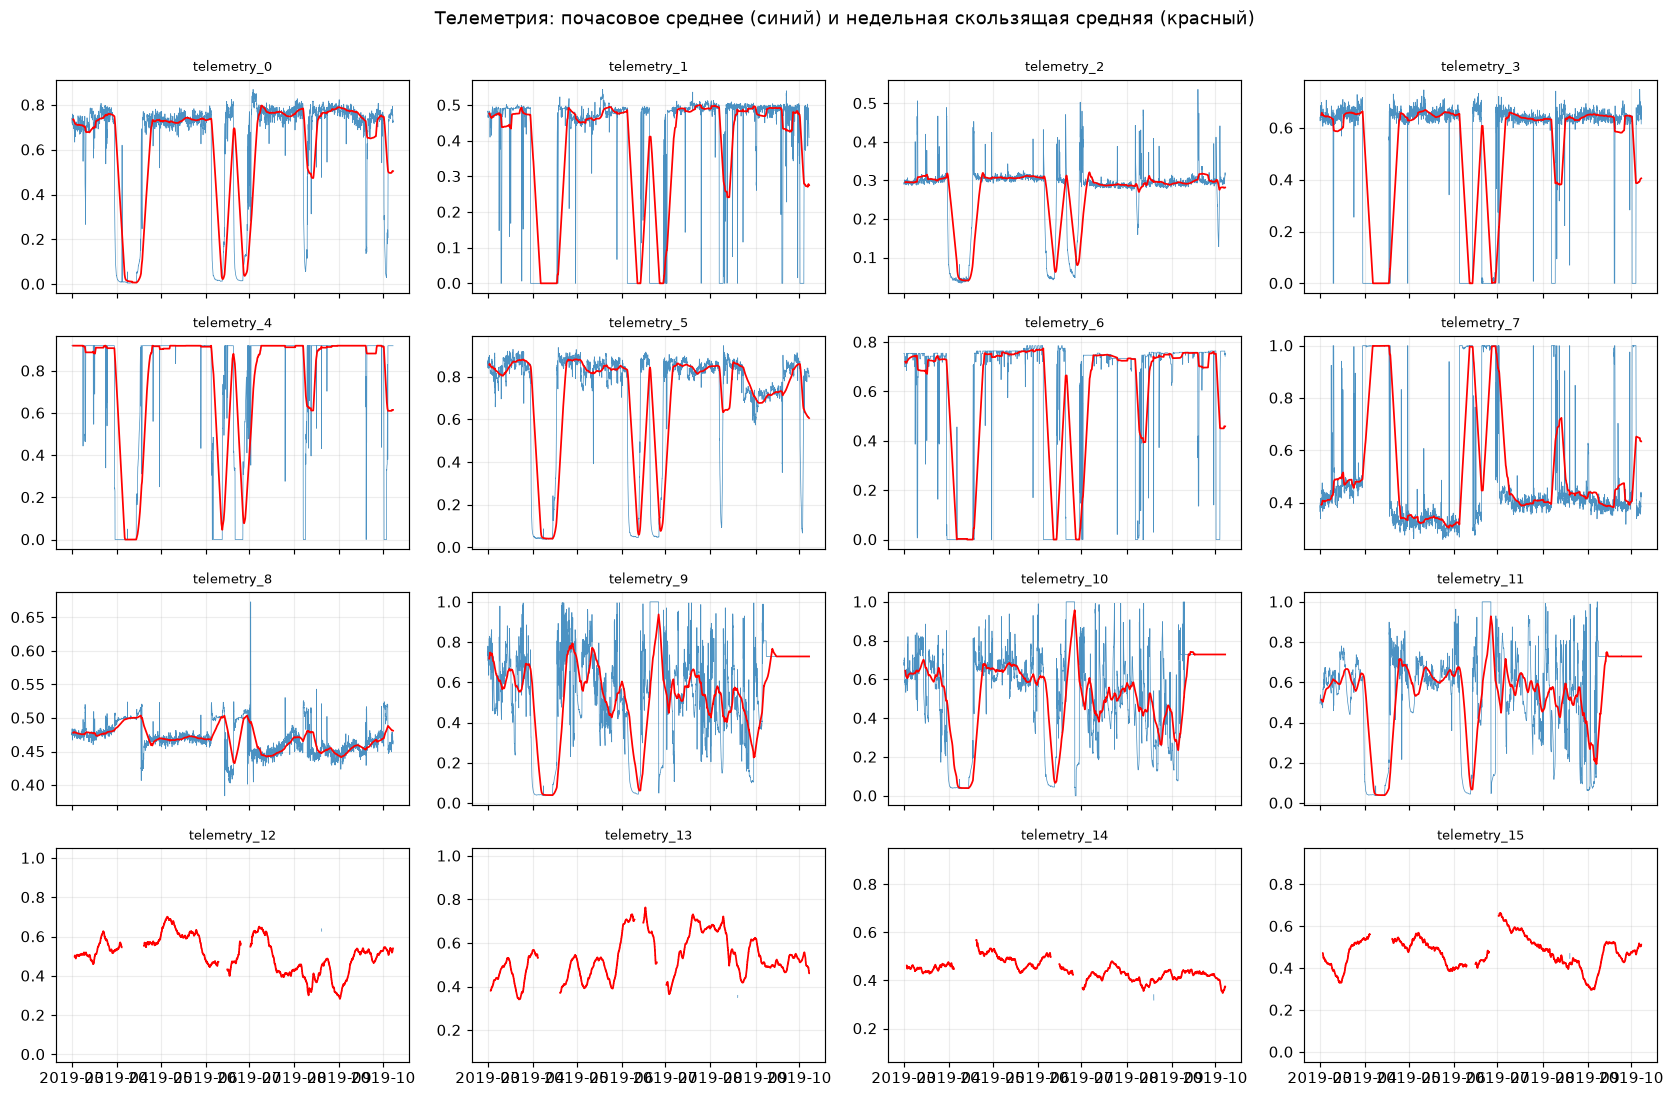

,count,mean,std,min,25%,50%,75%,max
telemetry_0,317981.0000,0.6100,0.2763,0.0035,0.6878,0.7390,0.7685,1.0000
telemetry_1,317982.0000,0.3800,0.1978,0.0000,0.4312,0.4861,0.4944,0.6108
telemetry_2,317982.0000,0.2668,0.0881,0.0318,0.2859,0.2957,0.3047,1.0000
telemetry_3,317982.0000,0.5201,0.2593,0.0000,0.6175,0.6395,0.6584,1.0000
telemetry_4,317865.0000,0.7620,0.3257,0.0000,0.9192,0.9195,0.9195,1.0000
telemetry_5,317981.0000,0.6959,0.2842,0.0000,0.7167,0.8295,0.8634,1.0000
telemetry_6,317982.0000,0.5940,0.3004,0.0000,0.7008,0.7492,0.7592,1.0000
telemetry_7,317982.0000,0.5227,0.2529,0.0206,0.3662,0.4108,0.4922,1.0000
telemetry_8,317982.0000,0.4696,0.0238,0.3440,0.4543,0.4679,0.4823,1.0000
telemetry_9,317982.0000,0.5358,0.2548,0.0000,0.3910,0.5818,0.7287,1.0000


In [6]:
hourly_tr = tele_grid_tr.resample('1h').mean()
ncol = 4; nrow = math.ceil(len(SENSORS) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 2.6 * nrow), sharex=True)
for ax, c in zip(axes.ravel(), SENSORS):
    ax.plot(hourly_tr.index, hourly_tr[c], lw=0.5, alpha=0.8)
    ax.plot(hourly_tr.index, hourly_tr[c].rolling(24 * 7, min_periods=24).mean(), color='red', lw=1.2)
    ax.set_title(c, fontsize=9)
fig.suptitle('Телеметрия: почасовое среднее (синий) и недельная скользящая средняя (красный)', y=1.0)
plt.tight_layout(); plt.show()

display(tele_grid_tr.describe().T)

#### Выбросы и форма распределений

По границам Тьюки можно увидеть, какие значения сильно отличаются от остальных. Пока оставляем их, так как это могут быть реальные изменения в работе печи.

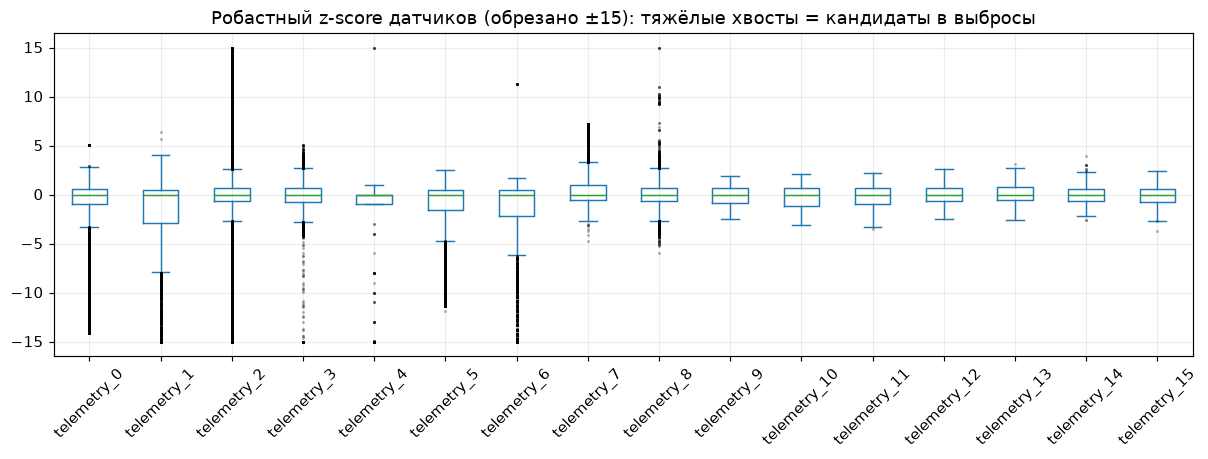

,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
"выбросы 1.5*IQR, %",21.2989,22.5385,21.2687,20.6070,21.3872,17.9941,22.0772,22.0074,1.2588,0.0000,0.0000,0.0006,0.0035,0.0031,0.0085,0.0025
"выбросы 3*IQR, %",20.2794,21.4168,19.3206,19.8495,21.3822,15.9369,21.2825,20.8699,0.0667,0.0000,0.0000,0.0000,0.0000,0.0000,0.0006,0.0000


In [7]:
def robust_z(df):
    med = df.median(); mad = (df - med).abs().median() * 1.4826
    iqr = df.quantile(.75) - df.quantile(.25)
    scale = mad.where(mad > 0, iqr).where(lambda s: s > 0)   # telemetry_4: MAD=0 -> берём IQR
    return (df - med) / scale

fig, ax = plt.subplots(figsize=(14, 4))
robust_z(tele_grid_tr.sample(min(len(tele_grid_tr), 100_000), random_state=SEED)).clip(-15, 15).plot.box(ax=ax, showfliers=True, flierprops=dict(markersize=1, alpha=0.3))
ax.set_title('Робастный z-score датчиков (обрезано ±15): тяжёлые хвосты = кандидаты в выбросы'); plt.xticks(rotation=45); plt.show()

q1, q3 = tele_grid_tr.quantile(0.25), tele_grid_tr.quantile(0.75); iqr = q3 - q1
out15 = ((tele_grid_tr < q1 - 1.5 * iqr) | (tele_grid_tr > q3 + 1.5 * iqr)).mean() * 100
out30 = ((tele_grid_tr < q1 - 3.0 * iqr) | (tele_grid_tr > q3 + 3.0 * iqr)).mean() * 100
display(pd.DataFrame({'выбросы 1.5*IQR, %': out15, 'выбросы 3*IQR, %': out30}).T)

#### Суточный и недельный профили. STL

Для STL интерполируем пропуски в почасовых данных. Этот ряд нужен только для графиков декомпозиции.

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\113913068.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  prof_dow = z_all.groupby(z_all.index.dayofweek).mean().T


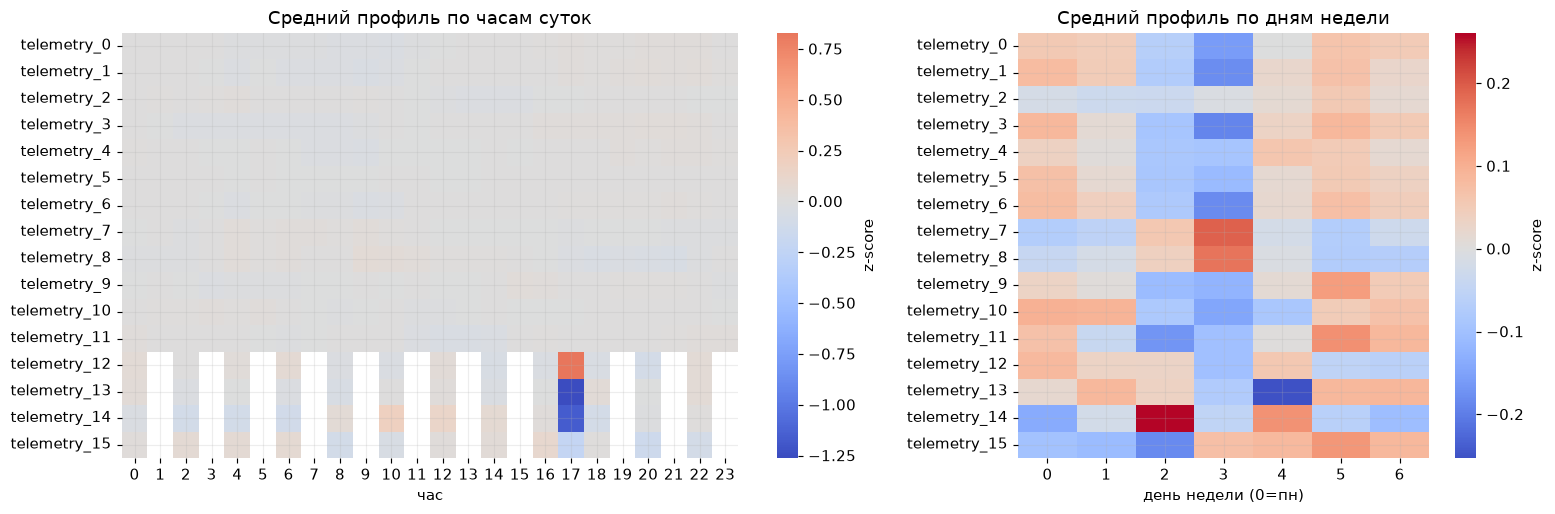

In [8]:
z_all = (tele_grid_tr - tele_grid_tr.mean()) / tele_grid_tr.std()
prof_hour = z_all.groupby(z_all.index.hour).mean().T
prof_dow = z_all.groupby(z_all.index.dayofweek).mean().T

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(prof_hour, cmap='coolwarm', center=0, ax=axes[0], cbar_kws={'label': 'z-score'}); axes[0].set_title('Средний профиль по часам суток'); axes[0].set_xlabel('час')
sns.heatmap(prof_dow, cmap='coolwarm', center=0, ax=axes[1], cbar_kws={'label': 'z-score'}); axes[1].set_title('Средний профиль по дням недели'); axes[1].set_xlabel('день недели (0=пн)')
plt.tight_layout(); plt.show()



,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8
F_суточная,0.3142,0.3364,0.2815,0.3601,0.3087,0.2784,0.3363,0.3336,0.3492
F_недельная,0.3978,0.4287,0.2286,0.4008,0.3666,0.3463,0.4290,0.4200,0.3711


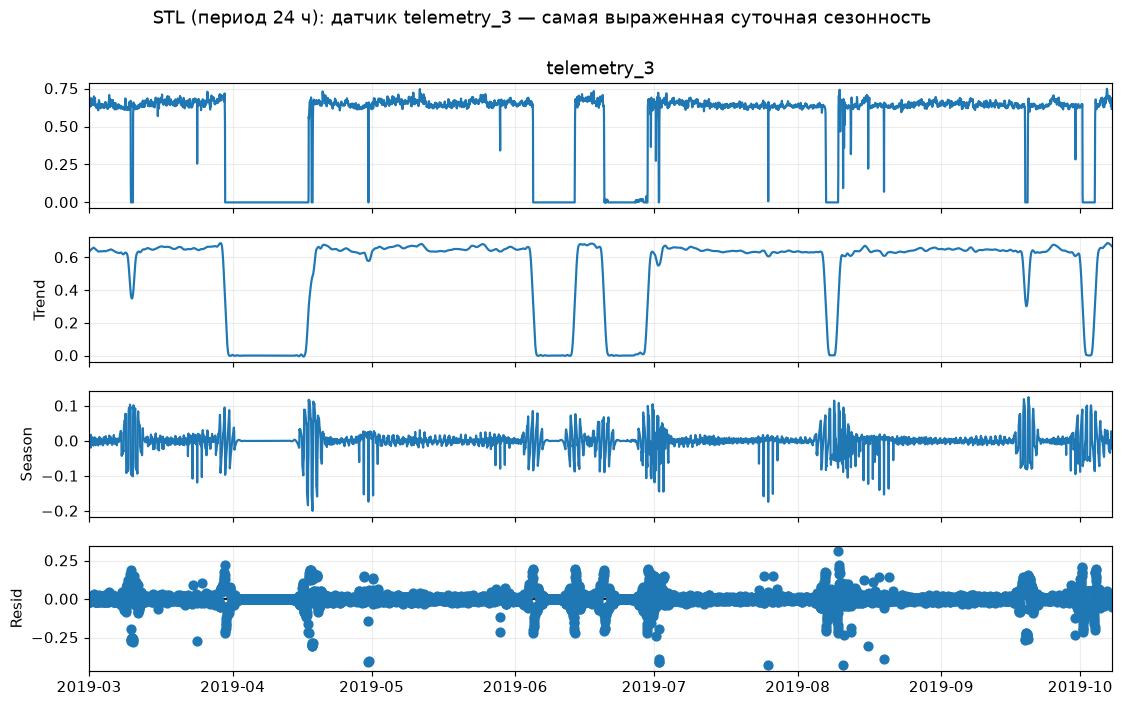

In [9]:
def seasonal_strength(x, period):
    res = STL(x, period=period, robust=False).fit()
    return max(0.0, 1 - np.var(res.resid) / np.var(res.resid + res.seasonal)), res

hourly_f = hourly_tr[ACTIVE].interpolate(limit_direction='both')
rows = {}
for c in ACTIVE:
    try:
        rows[c] = dict(F_суточная=seasonal_strength(hourly_f[c], 24)[0], F_недельная=seasonal_strength(hourly_f[c], 168)[0])
    except ValueError:
        rows[c] = dict(F_суточная=np.nan, F_недельная=np.nan)
season_tbl = pd.DataFrame(rows).T
display(season_tbl.T)

best_season = season_tbl['F_суточная'].astype(float).idxmax()
res_stl = STL(hourly_f[best_season], period=24, robust=False).fit()
fig = res_stl.plot(); fig.set_size_inches(12, 7); fig.subplots_adjust(top=.88); fig.suptitle(f'STL (период 24 ч): датчик {best_season} — самая выраженная суточная сезонность', y=.98); plt.show()

#### Стационарность телеметрии (ADF и KPSS)

In [10]:
def stationarity_row(x):
    x = x.dropna()
    if len(x) < 30 or x.std() == 0:
        return dict(ADF_p=np.nan, KPSS_p=np.nan, вывод='мало изменчивости')
    adf_p = adfuller(x, autolag='AIC')[1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        kp_p = kpss(x, regression='c', nlags='auto')[1]
    if adf_p < 0.05 and kp_p >= 0.05: verdict = 'стационарен'
    elif adf_p >= 0.05 and kp_p < 0.05: verdict = 'нестационарен (дрейф/тренд)'
    elif adf_p < 0.05 and kp_p < 0.05: verdict = 'тесты расходятся'
    else: verdict = 'неопределённо'
    return dict(ADF_p=adf_p, KPSS_p=kp_p, вывод=verdict)

stat_tbl = pd.DataFrame({c: stationarity_row(hourly_f[c]) for c in ACTIVE}).T
display(stat_tbl)
print(stat_tbl['вывод'].value_counts().to_string())

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\LOCALA~1

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\LOCALA~1

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\LOCALA~1

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\LOCALA~1

C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]


,ADF_p,KPSS_p,вывод
telemetry_0,0.0052,0.0100,тесты расходятся
telemetry_1,0.0007,0.0130,тесты расходятся
telemetry_2,0.0023,0.0100,тесты расходятся
telemetry_3,0.0010,0.0216,тесты расходятся
telemetry_4,0.0013,0.0102,тесты расходятся
telemetry_5,0.0020,0.0739,стационарен
telemetry_6,0.0006,0.0160,тесты расходятся
telemetry_7,0.0003,0.0349,тесты расходятся
telemetry_8,0.0000,0.0100,тесты расходятся


вывод
тесты расходятся    8
стационарен         1


### 2.1.2. Целевая переменная и частота замеров

Замеров: 1773; период: 2019-03-13 17:00:00 .. 2019-10-07 21:00:00
Интервал между замерами, мин: медиана=120, среднее=169, p5=120, p95=240, max=26430
Интервалы длиннее обычного (интервал > 1.5 × медианы): 197 из 1772 (11.1%); число интервалов >3 ч: 197


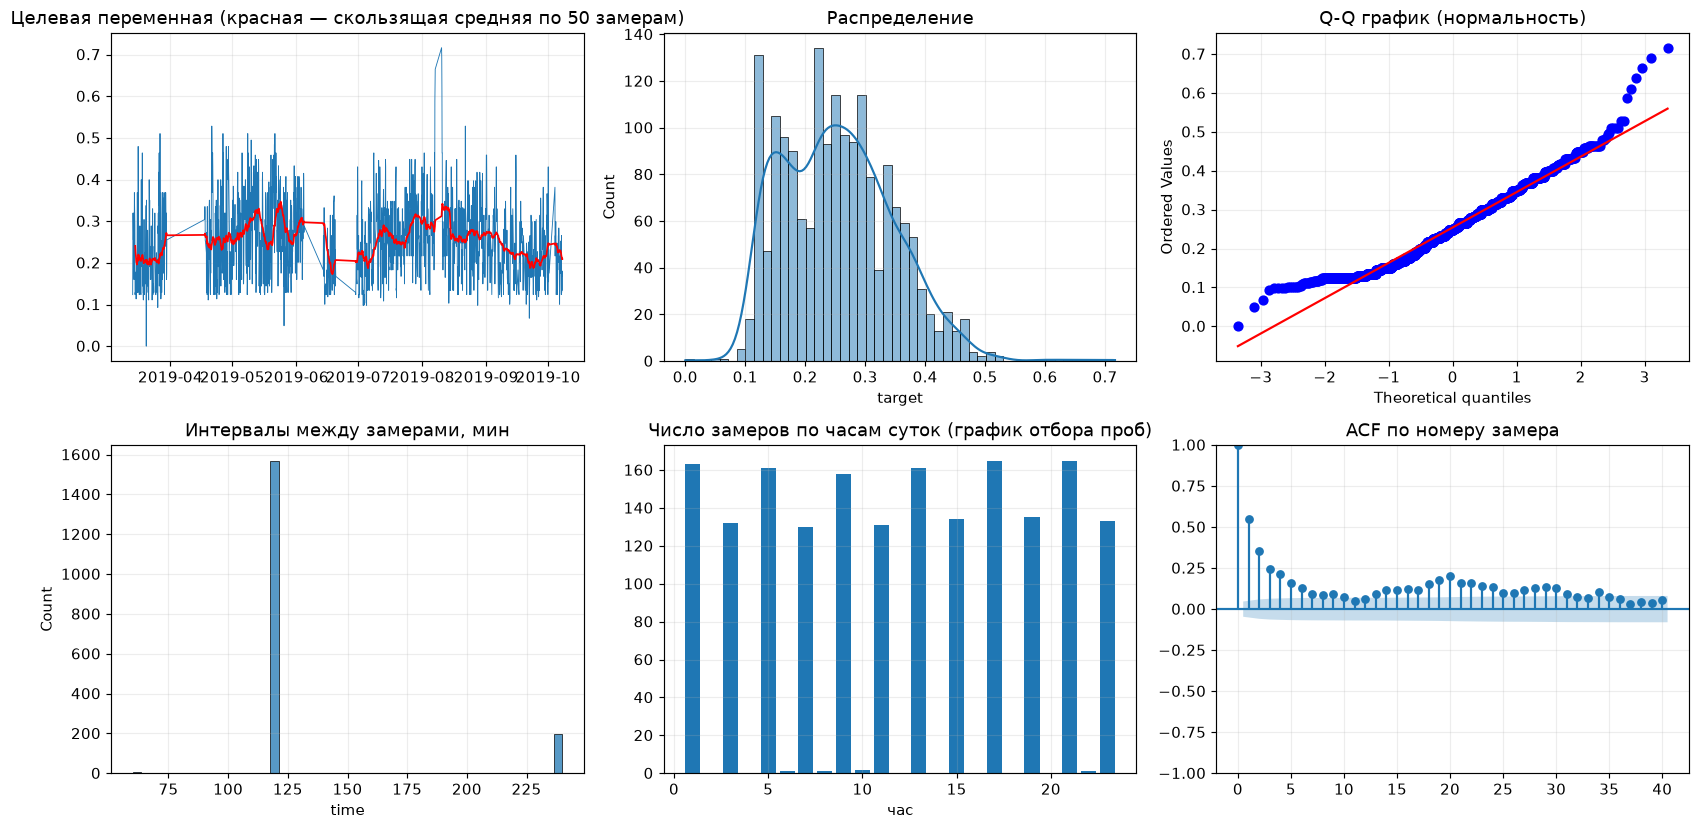

Асимметрия=0.550, эксцесс=0.419, Шапиро-Уилк p=8.47e-19
ADF/KPSS по порядку замеров: {'ADF_p': 1.1154001150664638e-06, 'KPSS_p': np.float64(0.06569501272616292), 'вывод': 'стационарен'}


C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]


,count,mean,std,min,25%,50%,75%,max
target,1773.0000,0.2543,0.0922,0.0000,0.1753,0.2474,0.3144,0.7165


In [11]:
y = y_raw_tr
dt_min = y.index.to_series().diff().dt.total_seconds().div(60).dropna()
med_dt = dt_min.median()
print(f'Замеров: {len(y)}; период: {y.index.min()} .. {y.index.max()}')
print(f'Интервал между замерами, мин: медиана={med_dt:.0f}, среднее={dt_min.mean():.0f}, p5={dt_min.quantile(.05):.0f}, p95={dt_min.quantile(.95):.0f}, max={dt_min.max():.0f}')
missed = (dt_min > 1.5 * med_dt)
print(f'Интервалы длиннее обычного (интервал > 1.5 × медианы): {missed.sum()} из {len(dt_min)} ({missed.mean():.1%}); '
      f'число интервалов >3 ч: {(dt_min > 180).sum()}')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes[0, 0].plot(y.index, y.values, lw=0.6); axes[0, 0].plot(y.index, y.rolling(50, min_periods=10).mean(), 'r', lw=1.2)
axes[0, 0].set_title('Целевая переменная (красная — скользящая средняя по 50 замерам)')
sns.histplot(y, kde=True, ax=axes[0, 1], bins=50); axes[0, 1].set_title('Распределение')
stats.probplot(y, dist='norm', plot=axes[0, 2]); axes[0, 2].set_title('Q-Q график (нормальность)')
sns.histplot(dt_min.clip(upper=dt_min.quantile(0.99)), bins=50, ax=axes[1, 0]); axes[1, 0].set_title('Интервалы между замерами, мин')
axes[1, 1].bar(*np.unique(y.index.hour, return_counts=True)); axes[1, 1].set_title('Число замеров по часам суток (график отбора проб)'); axes[1, 1].set_xlabel('час')
plot_acf(y.values, lags=40, ax=axes[1, 2]); axes[1, 2].set_title('ACF по номеру замера')
plt.tight_layout(); plt.show()

sk, ku = stats.skew(y), stats.kurtosis(y)
sh = stats.shapiro(y.sample(min(len(y), 5000), random_state=SEED))
print(f'Асимметрия={sk:.3f}, эксцесс={ku:.3f}, Шапиро-Уилк p={sh.pvalue:.2e}')
print('ADF/KPSS по порядку замеров:', stationarity_row(y))
display(y.describe().to_frame().T)

ACF и тесты для лабораторного ряда считаем по номеру пробы, так как интервалы между замерами разные. По длинному интервалу между двумя записями трудно сказать, пропустил ли оператор пробу.

### 2.1.3. Обработка пропусков, аномалий и смены режима

Иногда значения падают сразу у нескольких каналов, а на отдельных участках почти не меняются. Возможно, это смена режима печи, поэтому такие участки оставляем. В файлах нет отметок, по которым можно было бы отличить сбой датчика от реального изменения. Пропуски заполняем последним известным значением максимум на 15 минут, а с остальными модель работает на этапе подготовки входов.

Каналы с 9 по 11 почти перестают меняться в конце train. Каналы с 12 по 15 обновляются редко и неизвестно, когда их значения доступны оператору. Смотрим на них в EDA, а для модели оставляем девять других каналов.

Общего суточного профиля у датчиков не видно, поэтому берём скользящие окна и изменения сигналов. Среднее лабораторного ряда меняется по времени, поэтому для сравнения полезно взять ещё и прогноз по недавним пробам.

#### Режимы печи и различия между train и test

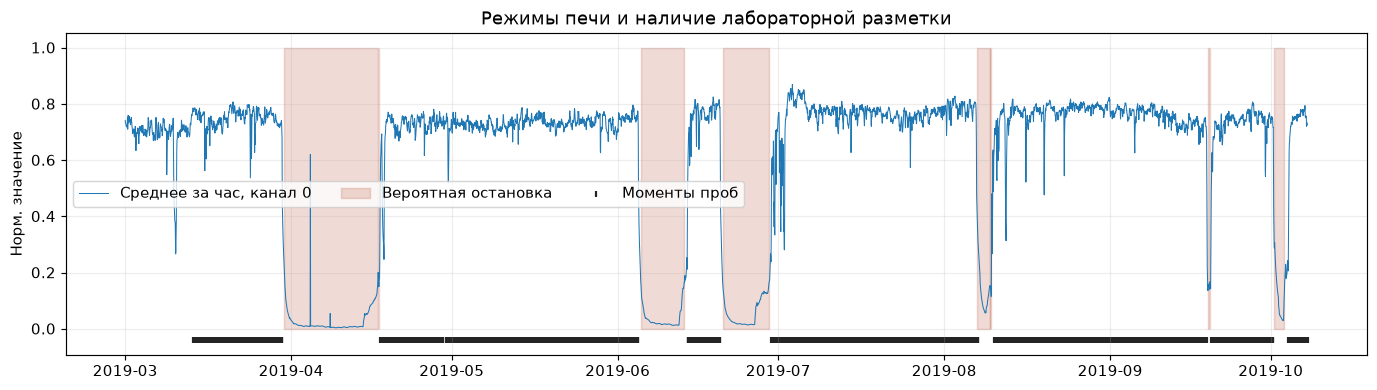

Доля минут в предполагаемой остановке: train 17.7%, test 0.0%.


,KS D,среднее train,среднее test,std test
telemetry_10,0.7371,0.5815,0.7287,0.0009
telemetry_11,0.7195,0.6016,0.7287,0.0017
telemetry_9,0.6673,0.5950,0.7287,0.0000
telemetry_6,0.4685,0.7200,0.7233,0.1471
telemetry_7,0.3649,0.4214,0.3958,0.1436
telemetry_8,0.2943,0.4627,0.4575,0.0172
цель,0.2831,0.2543,0.2097,0.0805
telemetry_4,0.2393,0.9023,0.8956,0.1096
telemetry_0,0.2291,0.7309,0.7467,0.0857
telemetry_1,0.2113,0.4607,0.4468,0.1080


In [12]:

off_cols = ['telemetry_0', 'telemetry_1', 'telemetry_3', 'telemetry_4', 'telemetry_5']

def probable_off(grid):
    levels = grid[off_cols].ffill(limit=MAX_FFILL_MIN)
    votes = levels.lt(.15).sum(axis=1) >= 3
    return votes.rolling(15, min_periods=1).median() >= .5

off_tr, off_te = probable_off(tele_grid_tr), probable_off(tele_grid_te)
h = tele_grid_tr['telemetry_0'].resample('h').mean()
off_hour = off_tr.resample('h').mean() > .5
fig, ax = plt.subplots(figsize=(13, 3.6), layout='constrained')
ax.plot(h.index, h, lw=.7, label='Среднее за час, канал 0')
ax.fill_between(h.index, 0, 1, where=off_hour, alpha=.18, color='#ac3618',
                label='Вероятная остановка')
ax.scatter(y_raw_tr.index, np.full(len(y_raw_tr), -.04), marker='|', s=12,
           color='#242424', label='Моменты проб')
ax.set(title='Режимы печи и наличие лабораторной разметки', ylabel='Норм. значение')
ax.legend(ncol=3)
plt.show()
print(f'Доля минут в предполагаемой остановке: train {off_tr.mean():.1%}, test {off_te.mean():.1%}.')

def sample_for_drift(col, grid, mask):
    s = grid.loc[~mask, col].dropna()
    return s.sample(min(25000, len(s)), random_state=SEED)

drift = {}
for col in DENSE:
    a = sample_for_drift(col, tele_grid_tr, off_tr)
    b = sample_for_drift(col, tele_grid_te, off_te)
    drift[col] = {'KS D': stats.ks_2samp(a, b).statistic, 'среднее train': a.mean(),
                  'среднее test': b.mean(), 'std test': b.std()}
drift['цель'] = {'KS D': stats.ks_2samp(y_raw_tr, y_raw_te).statistic,
                  'среднее train': y_raw_tr.mean(), 'среднее test': y_raw_te.mean(),
                  'std test': y_raw_te.std()}
display(pd.DataFrame(drift).T.sort_values('KS D', ascending=False))


По KS D можно посмотреть, насколько изменилось распределение между train и test. Соседние минуты зависимы, поэтому здесь смотрим на размер сдвига. Остановку печи определяем приблизительно по телеметрии, так как в данных нет разметки режимов.

#### Сезонность и стационарность на непрерывном рабочем интервале

In [13]:

working_hours = hourly_tr[ACTIVE].where(~off_hour).dropna()
segments = working_hours.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
work_segment = max((frame for _, frame in working_hours.groupby(segments)), key=len)
print(f'Длиннейший непрерывный рабочий интервал: {work_segment.index[0]} — {work_segment.index[-1]} '
      f'({len(work_segment)} ч).')
work_stats = {col: stationarity_row(work_segment[col]) for col in ACTIVE}
work_seas = {col: {f'STL {period} ч': seasonal_strength(work_segment[col], period)[0]
                   if len(work_segment) >= 2 * period else np.nan
                   for period in (24, 168)} for col in ACTIVE}
display(pd.DataFrame(work_stats).T.join(pd.DataFrame(work_seas).T))


Длиннейший непрерывный рабочий интервал: 2019-04-17 10:00:00 — 2019-05-31 10:00:00 (1057 ч).


C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\LOCALA~1\AppData\Local\Temp\ipykernel_18568\4121136154.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kp_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\LOCALA~1

,ADF_p,KPSS_p,вывод,STL 24 ч,STL 168 ч
telemetry_0,0.0000,0.0113,тесты расходятся,0.5917,0.5944
telemetry_1,0.0000,0.0241,тесты расходятся,0.5615,0.5703
telemetry_2,0.0000,0.0796,стационарен,0.5290,0.5861
telemetry_3,0.0000,0.0544,стационарен,0.5995,0.5773
telemetry_4,0.0000,0.0502,стационарен,0.5728,0.5577
telemetry_5,0.0000,0.0100,тесты расходятся,0.3615,0.5304
telemetry_6,0.0000,0.0100,тесты расходятся,0.5706,0.5680
telemetry_7,0.0000,0.0100,тесты расходятся,0.5238,0.5483
telemetry_8,0.0000,0.0100,тесты расходятся,0.5698,0.6029


### 2.1.4. Синхронизация телеметрии и лаборатории

Считаем, что время в CSV относится к отбору пробы. Если пробу взяли в 10 часов ровно, то её концентрация относится к 10 часов ровно и именно на эту минуту строим прогноз по телеметрии. Результат пробы можно использовать как вход только с 10 часов 12 минут. Эти 12 минут взяли как рабочее допущение из интервала от 10 до 15 минут в задании.

В CSV одна метка на пробу. Если она всё же относится к выдаче результата, то момент отбора надо оценить по более ранней телеметрии. Этот вариант отдельно проверяем в пункте 2.3.3. По метрикам можно сравнить допущения, но узнать точное время отбора из них нельзя.

In [14]:
def sample_time(lab, shift):
    out = lab.copy()
    out.index = out.index - pd.Timedelta(minutes=shift)
    return out

def clean_telemetry(grid):
    return grid[ACTIVE].replace([np.inf, -np.inf], np.nan).ffill(limit=MAX_FFILL_MIN)

shift = LAB_DELAY_MIN if LAB_TS_IS_RESULT_TIME else 0
train_labs, test_labs = sample_time(y_raw_tr, shift), sample_time(y_raw_te, shift)
all_labs = pd.concat([train_labs, test_labs]).sort_index()
assert all_labs.index.is_unique
ytr = train_labs.loc[tele_grid_tr.index.min():tele_grid_tr.index.max()]
yte = test_labs.loc[tele_grid_te.index.min():tele_grid_te.index.max()]
tele_tr = clean_telemetry(tele_grid_tr)
tele_both = clean_telemetry(to_full_grid(pd.concat([tele_raw_tr, tele_raw_te]).sort_index()))
print(f'На сетке телеметрии: train {len(ytr)}/{len(train_labs)}, test {len(yte)}/{len(test_labs)}')

На сетке телеметрии: train 1772/1773, test 318/318


In [15]:

sparse_timing = {}
for col in SPARSE:
    times = tele_raw_tr[col].dropna().index
    near = y_raw_tr.index[y_raw_tr.index.get_indexer(times, method='nearest')]
    offset = (times - near).total_seconds() / 60
    sparse_timing[col] = {'записей': len(times),
                          'медиана интервала, мин': times.to_series().diff().dt.total_seconds().median() / 60,
                          'наиболее частое смещение, мин': pd.Series(offset).mode().iloc[0]}
display(pd.DataFrame(sparse_timing).T)


,записей,"медиана интервала, мин","наиболее частое смещение, мин"
telemetry_12,2097.0000,120.0000,-60.0000
telemetry_13,2097.0000,120.0000,-60.0000
telemetry_14,2097.0000,120.0000,-60.0000
telemetry_15,2097.0000,120.0000,-60.0000


Здесь смотрим, за сколько минут до или после ближайшей пробы записываются редкие каналы. Время выдачи анализа в этих данных отдельно не записано.

### 2.1.5. Лаговые корреляции и динамические признаки

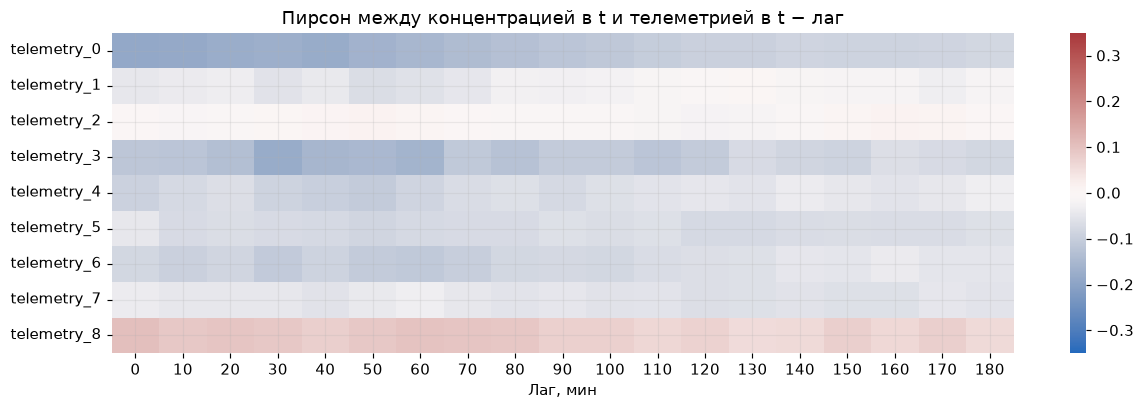

,максимум |r|
telemetry_0,0.1870
telemetry_3,0.1789
telemetry_6,0.1120
telemetry_4,0.1041
telemetry_8,0.1041
telemetry_5,0.0830
telemetry_1,0.0659
telemetry_7,0.0630
telemetry_2,0.0209


,Пирсон при лаге 0,Спирмен при лаге 0,"лаг макс. |r|, мин",макс. |r|
telemetry_0,-0.1870,-0.2121,0,0.1870
telemetry_3,-0.1175,-0.0660,30,0.1789
telemetry_6,-0.0818,-0.0527,60,0.1120
telemetry_4,-0.0908,-0.0081,50,0.1041
telemetry_8,0.1041,0.0663,0,0.1041
telemetry_5,-0.0457,-0.0873,50,0.0830
telemetry_1,-0.0440,-0.0381,50,0.0659
telemetry_7,-0.0361,-0.1120,120,0.0630
telemetry_2,-0.0032,-0.0231,120,0.0209


In [16]:
lags_eda = range(0, 181, 10)
lag_corr = pd.DataFrame({
    k: tele_tr.shift(k).reindex(ytr.index).corrwith(ytr)
    for k in lags_eda
})
plt.figure(figsize=(12, 4))
sns.heatmap(lag_corr, cmap='vlag', center=0, vmin=-.35, vmax=.35)
plt.title('Пирсон между концентрацией в t и телеметрией в t − лаг')
plt.xlabel('Лаг, мин')
plt.tight_layout()
plt.show()
display(lag_corr.abs().max(axis=1).sort_values(ascending=False).to_frame('максимум |r|'))

display(pd.DataFrame({
    'Пирсон при лаге 0': lag_corr[0],
    'Спирмен при лаге 0': tele_tr.reindex(ytr.index).corrwith(ytr, method='spearman'),
    'лаг макс. |r|, мин': lag_corr.abs().idxmax(axis=1),
    'макс. |r|': lag_corr.abs().max(axis=1),
}).sort_values('макс. |r|', ascending=False))


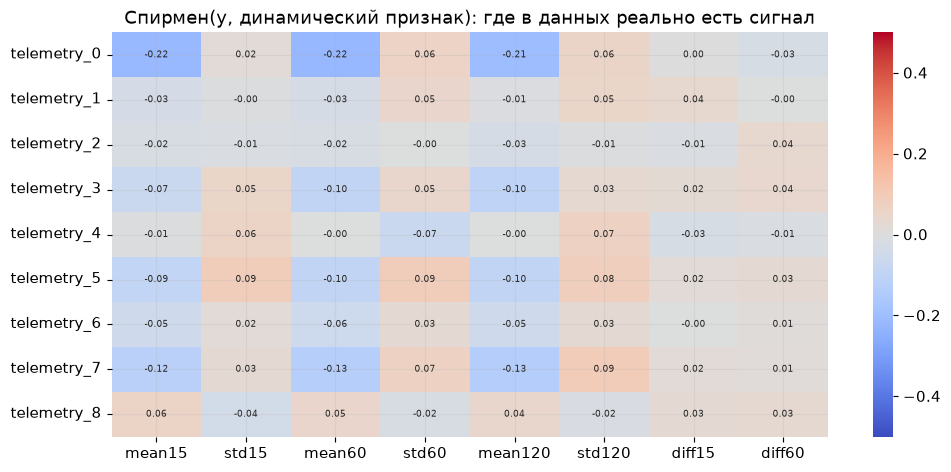

Топ-10 динамических признаков по |Спирмену|:


|rho|
telemetry_0 mean 60  0.2191
                 15  0.2152
                 120 0.2065
telemetry_7 mean 120 0.1338
                 60  0.1294
                 15  0.1185
telemetry_3 mean 120 0.1045
telemetry_5 mean 120 0.0973
telemetry_3 mean 60  0.0956
telemetry_5 mean 60  0.0951

In [17]:
def quick_feats(tele, times):
    out = {}
    for c in tele.columns:
        x = tele[c]
        for w in (15, 60, 120):
            r = x.rolling(w, min_periods=w // 2); out[(c, 'mean', w)] = r.mean().reindex(times); out[(c, 'std', w)] = r.std().reindex(times)
        for k in (15, 60): out[(c, 'diff', k)] = (x - x.shift(k)).reindex(times)
    return pd.DataFrame(out)
Q = quick_feats(tele_tr, ytr.index)
cq = Q.apply(lambda s: s.corr(ytr, method='spearman'))
cq_tbl = cq.unstack(level=[1, 2]); cq_tbl.columns = [f'{a}{b}' for a, b in cq_tbl.columns]
fig, ax = plt.subplots(figsize=(11, 5)); sns.heatmap(cq_tbl, cmap='coolwarm', center=0, vmin=-0.5, vmax=0.5, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax)
ax.set_title('Спирмен(y, динамический признак): где в данных реально есть сигнал'); plt.show()
print('Топ-10 динамических признаков по |Спирмену|:'); display(cq.abs().sort_values(ascending=False).head(10).to_frame('|rho|'))



### Выводы по пункту 2.1

Из 16 каналов 12 дают минутные данные, а четыре обновляются редко. Для модели оставляем девять, так как ещё три канала почти перестали меняться к концу train.

После сопоставления с телеметрией получилось 1772 пробы на train и 318 на test. Медианный разрыв между пробами составляет два часа, а средняя концентрация снизилась с 0,254 до 0,210. На тепловой карте выделяется среднее значение канала 0. Корреляция Спирмена около −0,22, так что связь есть, но она слабая.

## 2.2. Инжиниринг признаков для временных рядов

По минутным данным берём значения с лагами, средние, разброс и экстремумы в окнах до 360 минут. Также считаем разности, относительные изменения и экспоненциальные средние.

Для лаборатории берём несколько последних доступных результатов и время с отбора последней известной пробы, так как замеры идут нерегулярно. Ещё сравниваем текущее значение каждого датчика с его значением на момент этой пробы, чтобы учесть то, что успело измениться. Для относительного изменения ограничиваем знаменатель снизу, иначе при значениях датчика около нуля получаются слишком большие числа.

### 2.2.1. Лаги, скользящие статистики и изменения

In [18]:
SAFE = {c: c for c in ACTIVE}

def build_features(tele: pd.DataFrame, times, lags=LAGS, windows=WINDOWS, diffs=DIFFS, ewm_spans=EWM_SPANS) -> pd.DataFrame:
    """Причинные признаки для моментов `times` по полной минутной сетке `tele` (без заглядывания в будущее)."""
    times = pd.DatetimeIndex(times)
    parts = []
    for col in tele.columns:
        n = SAFE[col]
        x = tele[col].astype('float32')
        den_floor = 0.025           # защита темпа роста от деления на ~0 (масштаб из train)
        f = {f'{n}__raw': x}
        for k in lags:
            f[f'{n}__lag{k}'] = x.shift(k)
        for w in windows:
            r = x.rolling(w, min_periods=max(2, w // 2))      # правостороннее окно: [t-w+1, t]
            f[f'{n}__mean{w}'] = r.mean(); f[f'{n}__std{w}'] = r.std()
            f[f'{n}__min{w}'] = r.min();   f[f'{n}__max{w}'] = r.max()
        for k in diffs:
            xk = x.shift(k)
            f[f'{n}__diff{k}'] = x - xk
            f[f'{n}__rate{k}'] = ((x - xk) / xk.abs().clip(lower=den_floor)).clip(-5, 5)
        e_f = x.ewm(span=ewm_spans[0], adjust=False, ignore_na=True).mean()
        e_s = x.ewm(span=ewm_spans[1], adjust=False, ignore_na=True).mean()
        f[f'{n}__ewmfast'] = e_f; f[f'{n}__ewmslow'] = e_s; f[f'{n}__macd'] = e_f - e_s
        parts.append(pd.DataFrame(f).reindex(times))
    F = pd.concat(parts, axis=1).astype('float32')
    if USE_TIME_FEATURES:
        h = times.hour + times.minute / 60
        F['hour_sin'] = np.sin(2 * np.pi * h / 24).astype('float32'); F['hour_cos'] = np.cos(2 * np.pi * h / 24).astype('float32')
    return F

### 2.2.2. Известная лабораторная история и проверка причинности

In [19]:
LAB_CORE = ['lab__last', 'lab__mean3', 'lab__mean12', 'lab__age_h']
TELE_CORE = [f'{c}__{kind}' for c in ACTIVE for kind in ('mean60', 'diff60')]

def lab_history(labs, times, delay=LAB_DELAY_MIN):
    known = pd.DataFrame({'sample_time': labs.index, 'lab__last': labs.to_numpy()})
    for n in (2, 3, 5, 12, 36):
        known[f'lab__mean{n}'] = labs.rolling(n, min_periods=1).mean().to_numpy()
    known['lab__ewm'] = labs.ewm(halflife=3, adjust=False).mean().to_numpy()
    known['lab__previous'] = labs.shift().to_numpy()
    known['available'] = known['sample_time'] + pd.Timedelta(minutes=delay)
    joined = pd.merge_asof(pd.DataFrame({'time': times}), known,
                           left_on='time', right_on='available').set_index('time')
    joined['lab__age_h'] = (joined.index - joined['sample_time']).dt.total_seconds().div(3600)
    joined['lab__delta'] = joined['lab__last'] - joined['lab__previous']
    return joined

def inputs(tele, times, labs, delay=LAB_DELAY_MIN):
    times = pd.DatetimeIndex(times, name='time')
    hist = lab_history(labs, times, delay)
    tele_x = build_features(tele, times)
    anchor_at = tele.reindex(hist['sample_time'])
    change = tele.reindex(times) - anchor_at.set_axis(times)
    change.columns = [c + '__diff_since_lab' for c in change.columns]
    return pd.concat([tele_x, change, hist.filter(like='lab__')], axis=1)

Xtr = inputs(tele_tr, ytr.index, train_labs)
Xte = inputs(tele_both, yte.index, all_labs)
FEATS_TELE = [c for c in Xtr if not c.startswith('lab__') and not c.endswith('__diff_since_lab')]
FEATS_LINEAR = LAB_CORE + TELE_CORE
probe = ytr.index[len(ytr) // 2]
grid = tele_grid_tr.loc[probe - pd.Timedelta(hours=7):probe + pd.Timedelta(hours=1), ACTIVE]
a = clean_telemetry(grid)
b = clean_telemetry(grid.mask(grid.index.to_series() > probe, 9999, axis=0))
future_labs = train_labs.mask(train_labs.index + pd.Timedelta(minutes=LAB_DELAY_MIN) > probe, 9999)
np.testing.assert_allclose(inputs(a, [probe], train_labs), inputs(b, [probe], future_labs), equal_nan=True)
print(f'{len(FEATS_TELE)} признаков только по телеметрии, {Xtr.shape[1] - len(FEATS_TELE)} признаков используют историю проб.')
print('Тест пройден: будущая телеметрия и ещё не выданные замеры не меняют прогнозные входы.')

360 признаков только по телеметрии, 19 признаков используют историю проб.
Тест пройден: будущая телеметрия и ещё не выданные замеры не меняют прогнозные входы.


### 2.2.3. Отбор признаков и PCA

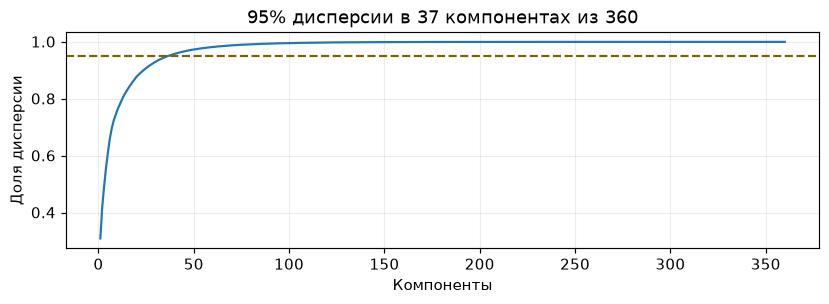

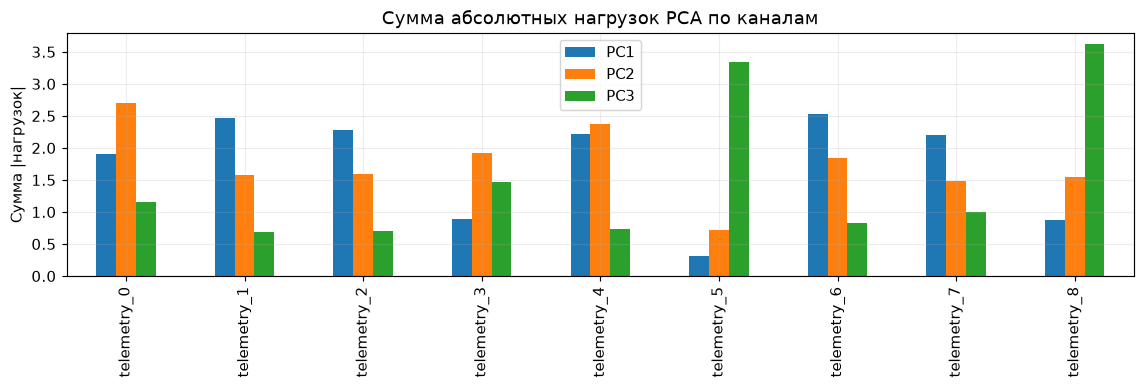

In [20]:
calibration_end = ytr.index[len(ytr) // 2]
z = make_pipeline(SimpleImputer(), StandardScaler()).fit_transform(Xtr.loc[:calibration_end, FEATS_TELE])
pca = PCA().fit(z)
cum_variance = pca.explained_variance_ratio_.cumsum()
plt.figure(figsize=(8, 3))
plt.plot(np.arange(1, len(cum_variance) + 1), cum_variance)
plt.axhline(.95, ls='--', color='#856000')
plt.xlabel('Компоненты')
plt.ylabel('Доля дисперсии')
plt.title(f'95% дисперсии в {np.searchsorted(cum_variance, .95) + 1} компонентах из {len(FEATS_TELE)}')
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(np.abs(pca.components_[:3]).T, index=FEATS_TELE, columns=['PC1', 'PC2', 'PC3'])
loadings.groupby(loadings.index.str.split('__').str[0]).sum().plot.bar(figsize=(11, 3.8))
plt.title('Сумма абсолютных нагрузок PCA по каналам')
plt.ylabel('Сумма |нагрузок|')
plt.tight_layout()
plt.show()


### 2.2.4. Разбиение данных по времени

Признаки считаем на минутной сетке, а учим модели и проверяем ошибки в моменты, когда есть проба. Внутри train делаем пять разбиений по времени и оставляем зазор в шесть часов перед валидацией. Параметры заполнения оставшихся пропусков и масштабирования считаем по обучающей части каждого разбиения.

### Выводы по пункту 2.2

По телеметрии получилось 360 признаков. Ещё 19 используют лабораторную историю, в том числе время предыдущей доступной пробы для сравнения показаний датчиков. Подменили будущие показания и ещё не выданные анализы на одной контрольной минуте, и входы для этой минуты остались такими же.

Для объяснения 95% разброса телеметрии понадобилось 37 компонент из 360 признаков. Похоже, соседние лаги и окна во многом повторяют друг друга. PCA здесь нужен, чтобы посмотреть на избыточность. Для ARX берём небольшой набор средних и разностей, LightGBM использует широкий набор признаков, а GRU получает последовательность пятиминутных средних.

## 2.3. Построение прогнозных моделей

Для начала сравним простые варианты. Можно взять среднее по train, последнюю доступную пробу или среднее нескольких проб. Ещё есть лабораторная AR, которая использует недавние результаты и давность последней пробы. С ней сравниваем модели по датчикам, так как предыдущие анализы уже дают информацию о текущем уровне концентрации.

### Почему выбрали эти модели

1. В ARX берём результаты доступных проб, а из телеметрии берём средние и изменения за заданное окно. Так можно проверить, достаточно ли линейной связи для оценки концентрации. Сравниваем OLS и Ridge, так как признаки одного канала могут быть похожи, а штраф Ridge помогает сдерживать рост коэффициентов.
2. LightGBM строит прогноз по небольшим деревьям. Связь между показанием одного датчика и концентрацией может меняться в зависимости от показаний другого датчика. Деревья могут учитывать такие связи. Глубину ограничиваем двумя или тремя уровнями, а размер листа держим от 25 наблюдений, так как целевых замеров в train около 1770. У выбранного варианта модель учится делать поправку к среднему трёх доступных проб.
3. У GRU входом служит последовательность пятиминутных средних, поэтому модель видит порядок изменений внутри окна. Также подаём признаки пропусков и доступную историю проб. Берём один рекуррентный слой на 8 или 16 скрытых состояний, так как меток мало и более крупной сети проще переобучиться.

### Какие варианты здесь не подходят

SARIMA по порядку проб здесь не подходит для минутного прогноза, так как интервалы между пробами разные и лаг в одну пробу не соответствует фиксированному числу минут. Если перенести концентрацию на минутную сетку и заполнить пробелы линейной интерполяцией по соседним пробам, то оценки между ними будут использовать следующий анализ раньше, чем он станет доступен.

Обычная RNN учитывает порядок показаний, но ей сложнее сохранять информацию на длинных последовательностях. LSTM и GRU позволяют управлять тем, какую информацию оставить в памяти. Обе архитектуры подходят для окон телеметрии, а GRU выбрали как более компактный вариант. Небольшую LSTM тоже можно было бы проверить, поэтому считать её заведомо неподходящей оснований нет. Для большой многослойной сети у нас мало целевых замеров и выше риск переобучения. Двунаправленная RNN не подходит в варианте, где для оценки концентрации в момент t используется телеметрия после этого момента. Тогда модель получает будущие данные. Если же обе стороны сети обрабатывают только уже доступное окно, которое заканчивается в момент t, такой вариант допустим. Поэтому ограничение связано с составом входных данных.

Логистическая регрессия для этой задачи не подходит, так как она даёт вероятность класса, а здесь нужна сама концентрация. Если бы мы хотели оценить вероятность выхода за заданный порог, тогда её можно было бы использовать для отдельной задачи.

N-BEATS, N-HiTS, Transformer мне кажутся чуть избыточными для такой задачи, так как много параметров надо настраивать, а где-то больше данных использовать.

Модель, которая на минуту прогноза берёт показания из центрированного окна или результат текущей пробы, тоже не подходит. В обоих случаях ей нужны данные, которых ещё нет в момент прогноза. Многослойную LSTM для первого сравнения было бы трудно обосновать, так как минутной телеметрии много, но целевых замеров около 1770. Поэтому для проверки последовательностей взяли компактную GRU.

Параметры выбираем по RMSE на следующих по времени блоках. Фиксируем набор каналов по состоянию в конце train, чтобы сравнивать модели на той же конфигурации датчиков, что и на test. На валидации предыдущая проба может стать входом после выдачи результата.

### 2.3.1. Бейзлайны, обучение и настройка

In [21]:
def gap_splits(index, n_splits=5):
    for tr, va in TimeSeriesSplit(n_splits=n_splits).split(index):
        cutoff = index[va[0]] - pd.Timedelta(minutes=GAP_MIN)
        yield tr[index[tr] < cutoff], va

def fit_ols(X, y, cols):
    prep = make_pipeline(SimpleImputer(), StandardScaler())
    z = prep.fit_transform(X[cols])
    fit = sm.OLS(y.to_numpy(), sm.add_constant(z, has_constant='add')).fit()
    return (lambda x: fit.predict(sm.add_constant(prep.transform(x[cols]), has_constant='add'))), fit

def fit_candidate(spec, X, y):
    kind, cols, param, anchor, weight = spec
    mu = y.mean()
    if kind == 'mean':
        return lambda x: np.full(len(x), mu)
    if kind == 'history':
        return lambda x: x[anchor].fillna(mu).to_numpy()
    if kind == 'ols':
        return fit_ols(X, y, cols)[0]
    if kind == 'ridge':
        model = make_pipeline(SimpleImputer(), StandardScaler(), Ridge(alpha=param))
    else:
        n, depth = param
        model = lgb.LGBMRegressor(n_estimators=n, max_depth=depth, num_leaves=2**depth,
                                  learning_rate=.035, min_child_samples=45, reg_lambda=10,
                                  colsample_bytree=.65, n_jobs=2, random_state=SEED, verbosity=-1)
    level = X[anchor].fillna(mu) if anchor else 0
    model.fit(X[cols], y - level)

    def predict(x):
        base = x[anchor].fillna(mu).to_numpy() if anchor else 0
        matrix = x[cols]
        if kind == 'lgbm':
            correction = model.predict(matrix, validate_features=True)
        else:
            correction = model.predict(matrix)
        return base + weight * correction

    predict.model = model
    return predict

In [22]:
specs = {
    'train_mean': ('mean', [], None, None, 1),
    'last_lab': ('history', [], None, 'lab__last', 1),
    'lab_ar': ('ols', LAB_CORE, None, None, 1),
    'ols_arx': ('ols', FEATS_LINEAR, None, None, 1),
}
family = {name: name for name in specs}
for n in (2, 3, 5, 12, 36, 'ewm'):
    name = f'lab_smooth_{n}'
    family[name] = 'lab_smooth'
    specs[name] = ('history', [], None, 'lab__ewm' if n == 'ewm' else f'lab__mean{n}', 1)
for alpha in (30, 150, 600, 2400):
    name = f'ridge_tele_{alpha}'
    family[name] = 'ridge_tele'
    specs[name] = ('ridge', FEATS_TELE, alpha, None, 1)
    name = f'ridge_slow_{alpha}'
    family[name] = 'ridge_slow'
    specs[name] = ('ridge', FEATS_TELE, alpha, 'lab__mean36', 1)
    for w in (.35, .7, 1):
        name = f'ridge_arx_{alpha}_{w}'
        specs[name] = ('ridge', list(Xtr.columns), alpha, 'lab__mean3', w)
        family[name] = 'ridge_arx'
for n, depth in ((25, 2), (75, 2), (150, 2), (75, 3), (150, 3)):
    name = f'lgbm_tele_{n}_{depth}'
    family[name] = 'lgbm_tele'
    specs[name] = ('lgbm', FEATS_TELE, (n, depth), None, 1)
    for w in (.35, .7, 1):
        name = f'lgbm_arx_{n}_{depth}_{w}'
        specs[name] = ('lgbm', list(Xtr.columns), (n, depth), 'lab__mean3', w)
        family[name] = 'lgbm_arx'

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - p) ** 2)))

def cv_predictions(spec, X, y):
    out = []
    for fold, (tr, va) in enumerate(gap_splits(y.index), start=1):
        predictor = fit_candidate(spec, X.iloc[tr], y.iloc[tr])
        out.append(pd.DataFrame({'fact': y.iloc[va], 'pred': predictor(X.iloc[va]), 'fold': fold}))
    return pd.concat(out)

cv = {name: cv_predictions(spec, Xtr, ytr) for name, spec in specs.items()}
selection = pd.DataFrame({
    name: {'family': family[name], 'CV_RMSE': rmse(p.fact, p.pred),
           'CV_MAE': np.abs(p.fact - p.pred).mean()}
    for name, p in cv.items()
}).T.sort_values('CV_RMSE')
chosen = selection.drop_duplicates('family').copy()
best_lab = chosen.index[chosen['family'].isin(['lab_smooth', 'lab_ar', 'last_lab'])][0]
best_hybrid = chosen.index[chosen['family'].isin(['ols_arx', 'ridge_arx', 'lgbm_arx', 'ridge_slow'])][0]
best_tele = chosen.index[chosen['family'].isin(['ridge_tele', 'lgbm_tele'])][0]
chosen_names = chosen.index.tolist()
display(chosen)
print(f'Зафиксировано по CV: история — {best_lab}; гибрид — {best_hybrid}; только телеметрия — {best_tele}')
print('RMSE по блокам:')
display(pd.DataFrame({name: cv[name].groupby('fold').apply(
    lambda p: rmse(p.fact, p.pred), include_groups=False) for name in chosen_names}).T)

,family,CV_RMSE,CV_MAE
lab_ar,lab_ar,0.0759,0.0602
lgbm_arx_75_3_1,lgbm_arx,0.0767,0.0605
ols_arx,ols_arx,0.0786,0.0621
ridge_arx_2400_0.7,ridge_arx,0.0810,0.0629
lab_smooth_ewm,lab_smooth,0.0815,0.0642
last_lab,last_lab,0.0847,0.0643
ridge_slow_2400,ridge_slow,0.0905,0.0692
lgbm_tele_25_2,lgbm_tele,0.0911,0.0731
train_mean,train_mean,0.0933,0.0750
ridge_tele_2400,ridge_tele,0.0952,0.0744


Зафиксировано по CV: история — lab_ar; гибрид — lgbm_arx_75_3_1; только телеметрия — lgbm_tele_25_2
RMSE по блокам:


fold,1,2,3,4,5
lab_ar,0.0902,0.0706,0.0688,0.0801,0.0673
lgbm_arx_75_3_1,0.0892,0.0726,0.0700,0.0794,0.0705
ols_arx,0.0843,0.0848,0.0685,0.0809,0.0732
ridge_arx_2400_0.7,0.0964,0.0783,0.0728,0.0830,0.0719
lab_smooth_ewm,0.0958,0.0750,0.0748,0.0889,0.0702
last_lab,0.0982,0.0790,0.0793,0.0885,0.0765
ridge_slow_2400,0.0950,0.1005,0.0764,0.1026,0.0738
lgbm_tele_25_2,0.1013,0.0830,0.0809,0.1017,0.0862
train_mean,0.1111,0.0888,0.0799,0.0993,0.0843
ridge_tele_2400,0.0991,0.0954,0.0810,0.1044,0.0947


### 2.3.2. Хронологическое разбиение и устойчивость качества

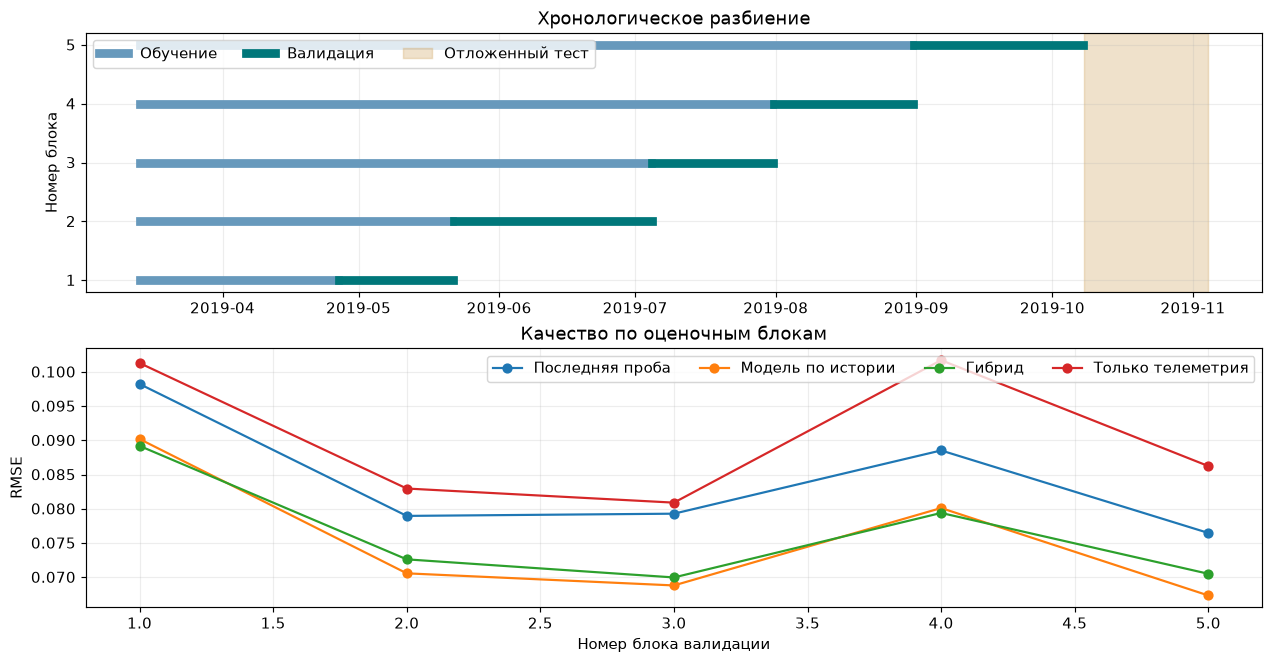

In [23]:

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), layout='constrained')
for fold, (tr, val) in enumerate(gap_splits(ytr.index), 1):
    axes[0].plot(ytr.index[tr[[0, -1]]], [fold] * 2, lw=6, color='#6799bc',
                 label='Обучение' if fold == 1 else None)
    axes[0].plot(ytr.index[val[[0, -1]]], [fold] * 2, lw=6, color='#00777a',
                 label='Валидация' if fold == 1 else None)
axes[0].axvspan(yte.index[0], yte.index[-1], color='#d2aa6b', alpha=.35, label='Отложенный тест')
axes[0].set(title='Хронологическое разбиение', ylabel='Номер блока')
axes[0].legend(ncol=3, loc='upper left')
for name, label in [('last_lab', 'Последняя проба'), (best_lab, 'Модель по истории'),
                    (best_hybrid, 'Гибрид'), (best_tele, 'Только телеметрия')]:
    scores = cv[name].groupby('fold').apply(lambda p: rmse(p.fact, p.pred), include_groups=False)
    axes[1].plot(scores.index, scores, marker='o', label=label)
axes[1].set(xlabel='Номер блока валидации', ylabel='RMSE', title='Качество по оценочным блокам')
axes[1].legend(ncol=4)
plt.show()


### 2.3.3. Чувствительность к задержке лаборатории

In [ ]:
sensitivity = {}
for assumed_shift in (0, 10, 12, 15):
    labs = sample_time(y_raw_tr, assumed_shift)
    values = labs.loc[tele_grid_tr.index.min():tele_grid_tr.index.max()]
    common_stamps = values.index + pd.Timedelta(minutes=assumed_shift)
    selected = common_stamps.isin(y_raw_tr.loc[tele_grid_tr.index.min() + pd.Timedelta(minutes=15):
                                                tele_grid_tr.index.max()].index)
    values = values[selected]
    design = inputs(tele_tr, values.index, labs, delay=assumed_shift or LAB_DELAY_MIN)
    results = {name: cv_predictions(specs[name], design, values)
               for name in (best_tele, best_hybrid)}
    sensitivity[assumed_shift] = {name: rmse(p.fact, p.pred) for name, p in results.items()}
display(pd.DataFrame(sensitivity).T.rename_axis('Сдвиг метки назад, мин'))

,lgbm_tele_25_2,lgbm_arx_75_3_1
"Сдвиг метки назад, мин",,
0,0.0911,0.0767
10,0.0910,0.0765
12,0.0910,0.0767
15,0.0909,0.0763


### Выводы по первому сравнению моделей

На временной валидации лабораторная AR дала RMSE 0,0759, а LightGBM с историей проб дал 0,0767. Только по телеметрии у LightGBM получилось 0,0911. При проверке альтернативной привязки сдвиг на 10, 12 или 15 минут мало меняет RMSE этих вариантов.

### 2.3.3а. Сравнение преобразований и параметров ARX, LightGBM и GRU

Проверяем 72 варианта на пяти разбиениях с растущей обучающей частью и зазором в 360 минут. Из каждого семейства берём модель с наименьшим RMSE по всем прогнозам на валидационных блоках. Ошибки считаем в исходной шкале. Также смотрим MAE, совпадение направления и RMSE отдельно по блокам. Настройки этого эксперимента выбираем по train, хотя сам тестовый период уже смотрели в прошлых версиях работы.

Для ARX берём четыре признака из лабораторной истории и средние и разности девяти каналов за 15 или 60 минут. Сравниваем OLS и Ridge с α 30 или 300, а для входов проверяем StandardScaler и RobustScaler.

Для LightGBM проверяем от 50 до 150 деревьев глубины 2 или 3, а минимальный размер листа составляет 25 или 45 наблюдений. Есть прямой прогноз и вариант с поправкой к среднему трёх доступных проб. Признаки оставляем в исходной шкале.

У GRU один рекуррентный слой на 8 или 16 скрытых состояний. Подаём пятиминутные средние за последний час или три часа, признаки пропусков и историю доступных проб. Последнее среднее заканчивается в минуту прогноза, а скрытое состояние сбрасываем между окнами. Сравниваем 20, 40 и 80 эпох, шаг обучения 0,001 или 0,003, прямой прогноз и поправку к истории. Для входов пробуем стандартное и робастное масштабирование, а ещё нормализацию каждого окна отдельно. В последнем случае теряется общий уровень сигнала внутри окна.

Для таргета в разных вариантах проверяем исходную шкалу, стандартизацию, квадратный корень, Box–Cox и Yeo–Johnson. Для Box–Cox прибавляем 0,001, так как в train есть ноль. Параметр λ, масштабирование и значения для заполнения пропусков считаем по обучающей части каждого разбиения. Для нелинейных вариантов дополнительно стандартизируем преобразованную цель и возвращаем прогноз в исходную шкалу перед расчётом метрик. По RMSE и смещению можно посмотреть, помогло ли это. У OLS и Ridge при том же α простая стандартизация таргета после обратного преобразования даёт практически такой же прогноз.

У выбранной GRU дополнительно проверяем ещё два значения seed. Число эпох выбираем по валидации. Новые результаты проб на validation и test добавляем в историю после принятой задержки выдачи.

Эксперименты я чисто для себя делал, чтобы посмотреть, влияют ли преобразования и подбор параметров на прогноз. Потом оставил варианты, которые лучше показали себя на временной валидации.

Если сохранённых результатов нет, ноутбук обучит модели заново и сам создаст папку с результатами.

In [ ]:
torch.set_num_threads(2)

experiment_source = get_ipython().history_manager.input_hist_raw[-1].encode()

class TargetMap:
    def __init__(self, kind):
        self.kind = kind

    def fit(self, y):
        y = np.asarray(y, dtype=float)
        if self.kind == 'boxcox':
            self.shift = .001
            self.lam = stats.boxcox_normmax(y + self.shift, method='mle')
        if self.kind == 'yeojohnson':
            self.power = PowerTransformer(method='yeo-johnson', standardize=False).fit(y[:, None])
        self.scaler = StandardScaler().fit(self.nonlinear(y)[:, None])
        return self

    def nonlinear(self, y):
        y = np.asarray(y, dtype=float)
        if self.kind == 'sqrt':
            return np.sqrt(np.maximum(y, 0))
        if self.kind == 'boxcox':
            return special.boxcox(np.maximum(y + self.shift, 1e-8), self.lam)
        if self.kind == 'yeojohnson':
            return self.power.transform(y[:, None]).ravel()
        return y

    def transform(self, y):
        z = self.nonlinear(y)
        return z if self.kind == 'raw' else self.scaler.transform(z[:, None]).ravel()

    def inverse(self, z):
        z = np.asarray(z, dtype=float)
        if self.kind != 'raw':
            z = self.scaler.inverse_transform(z[:, None]).ravel()
        if self.kind == 'sqrt':
            return np.maximum(z, 0)**2
        if self.kind == 'boxcox':
            if self.lam > 0:
                z = np.maximum(z, -1 / self.lam + 1e-8)
            elif self.lam < 0:
                z = np.minimum(z, -1 / self.lam - 1e-8)
            return special.inv_boxcox(z, self.lam) - self.shift
        if self.kind == 'yeojohnson':
            return self.power.inverse_transform(z[:, None]).ravel()
        return z


def sequence_windows(tele, times, minutes):
    """5-min right-aligned means at t,t-5,...; raw missingness retained."""
    smooth = tele.rolling(5, min_periods=1).mean()
    times = pd.DatetimeIndex(times)
    return np.stack([smooth.reindex(times - pd.Timedelta(minutes=k)).to_numpy()
                     for k in range(minutes - 5, -1, -5)], axis=1).astype('float32')


class SmallGRU(nn.Module):
    def __init__(self, channels, context, hidden):
        super().__init__()
        self.gru = nn.GRU(channels, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + context, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, seq, context):
        _, h = self.gru(seq)
        return self.head(torch.cat([h[-1], context], dim=1)).squeeze(1)


class GRUPredictor:
    def __init__(self, cfg, seed=42):
        self.cfg, self.seed = cfg, seed

    def prepare(self, seq, context, fit=False):
        n, steps, channels = seq.shape
        if fit:
            self.median = np.nanmedian(seq.reshape(-1, channels), axis=0)
            self.median = np.nan_to_num(self.median)
        mask = ~np.isfinite(seq)
        z = np.where(mask, self.median, seq)
        if fit:
            scaler = RobustScaler() if self.cfg['scale'] == 'robust' else StandardScaler()
            self.scaler = scaler.fit(z.reshape(-1, channels))
            self.context = make_pipeline(SimpleImputer(), StandardScaler()).fit(context)
        z = self.scaler.transform(z.reshape(-1, channels)).reshape(n, steps, channels)
        if self.cfg['scale'] == 'window':
            z = (z - z.mean(axis=1, keepdims=True)) / np.maximum(z.std(axis=1, keepdims=True), 1e-4)
        z = np.concatenate([z, mask.astype(float)], axis=-1)
        c = self.context.transform(context)
        return torch.tensor(z, dtype=torch.float32), torch.tensor(c, dtype=torch.float32)

    def fit(self, seq, context, y, epochs):
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        x, c = self.prepare(seq, context, fit=True)
        self.map = TargetMap(self.cfg['target']).fit(y)
        self.mu = float(np.mean(y))
        base = context['lab__mean3'].fillna(self.mu).to_numpy()
        self.anchor = self.map.transform(base) if self.cfg['anchor'] else np.zeros(len(y))
        t = torch.tensor(self.map.transform(y) - self.anchor, dtype=torch.float32)
        self.net = SmallGRU(x.shape[-1], c.shape[-1], self.cfg['hidden'])
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.cfg['lr'], weight_decay=.01)
        self.net.train()
        self.history = []
        for epoch in range(epochs):
            order = torch.randperm(len(t))
            loss_sum = 0.
            for ix in order.split(64):
                opt.zero_grad()
                p = self.net(x[ix], c[ix])
                loss = ((p - t[ix])**2).mean()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 1.)
                opt.step()
                loss_sum += loss.item() * len(ix)
            self.history.append(loss_sum / len(t))
        self.net.eval()
        return self

    def predict(self, seq, context):
        x, c = self.prepare(seq, context)
        with torch.no_grad():
            z = torch.cat([self.net(x[i:i+256], c[i:i+256]) for i in range(0, len(x), 256)]).numpy()
        if self.cfg['anchor']:
            z += self.map.transform(context['lab__mean3'].fillna(self.mu).to_numpy())
        return self.map.inverse(z)


def fit_tabular(cfg, X, y, active, lab_cols):
    if cfg['family'] == 'ARX':
        cols = lab_cols + [f'{c}__{kind}{cfg["window"]}' for c in active for kind in ('mean', 'diff')]
        scaler = RobustScaler() if cfg.get('scale') == 'robust' else StandardScaler()
        estimator = LinearRegression() if cfg['alpha'] == 0 else Ridge(alpha=cfg['alpha'])
        model = make_pipeline(SimpleImputer(), scaler, estimator)
    else:
        cols = list(X.columns)
        model = lgb.LGBMRegressor(n_estimators=cfg['trees'], max_depth=cfg['depth'],
            num_leaves=2**cfg['depth'], min_child_samples=cfg['leaf'], learning_rate=.035,
            reg_lambda=10, colsample_bytree=.8, verbosity=-1, n_jobs=2, random_state=42)
    target = TargetMap(cfg['target']).fit(y)
    mu = y.mean()
    base = target.transform(X['lab__mean3'].fillna(mu)) if cfg.get('anchor') else 0
    model.fit(X[cols], target.transform(y) - base)

    def predict(x):
        b = target.transform(x['lab__mean3'].fillna(mu)) if cfg.get('anchor') else 0
        return target.inverse(model.predict(x[cols]) + b)

    predict.model, predict.columns, predict.target_map = model, cols, target
    return predict


def configurations():
    configs = []
    for window in (15, 60):
        for alpha in (0, 30, 300):
            for target in ('raw', 'standard', 'sqrt', 'boxcox', 'yeojohnson'):
                configs.append(dict(family='ARX', window=window, alpha=alpha, target=target, scale='standard'))
    for alpha in (30, 300):
        configs.append(dict(family='ARX', window=60, alpha=alpha, target='standard', scale='robust'))
    for trees, depth, leaf in ((50, 2, 45), (150, 2, 45), (100, 3, 25)):
        for anchor in (False, True):
            for target in ('raw', 'sqrt', 'boxcox', 'yeojohnson'):
                configs.append(dict(family='LightGBM', trees=trees, depth=depth, leaf=leaf,
                                    target=target, anchor=anchor))
    for window in (60, 180):
        for hidden in (8, 16):
            for anchor in (False, True):
                configs.append(dict(family='GRU', window=window, hidden=hidden, anchor=anchor,
                                    target='standard', scale='standard', lr=.003, epochs=40))
    for target in ('raw', 'sqrt', 'boxcox', 'yeojohnson'):
        configs.append(dict(family='GRU', window=60, hidden=8, anchor=True,
                            target=target, scale='standard', lr=.003, epochs=40))
    for scale in ('robust', 'window'):
        configs.append(dict(family='GRU', window=60, hidden=8, anchor=True,
                            target='standard', scale=scale, lr=.003, epochs=40))
    for epochs, lr in ((20, .003), (80, .001)):
        configs.append(dict(family='GRU', window=60, hidden=8, anchor=True,
                            target='standard', scale='standard', lr=lr, epochs=epochs))
    return {f'{c["family"]}_{i:03d}': c for i, c in enumerate(configs)}


def direction(y, p, index):
    dy, dp = np.diff(y), np.diff(p)
    good = (dy != 0) & (np.diff(index) / np.timedelta64(1, 'm') <= 360)
    return 100 * np.mean(np.sign(dy[good]) == np.sign(dp[good]))


def experiment_search(X, y, tele, active, lab_cols, splits, directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    configs = configurations()
    seq = {w: sequence_windows(tele, y.index, w) for w in (60, 180)}
    context_cols = list(X.filter(like='lab__').columns)
    folds = list(splits)
    digest = hashlib.sha256(experiment_source + pd.util.hash_pandas_object(X).values.tobytes()
                            + pd.util.hash_pandas_object(y).values.tobytes()
                            + json.dumps(configs, sort_keys=True).encode())
    for w in seq:
        digest.update(seq[w].tobytes())
    for tr, va in folds:
        digest.update(tr.tobytes() + va.tobytes())
    cache = directory / digest.hexdigest()[:16]
    cache.mkdir(exist_ok=True)
    records, out = [], {}
    for name, cfg in configs.items():
        path = cache / f'{name}.csv'
        start = time.perf_counter()
        timings_path = path.with_suffix('.json')
        if path.is_file() and timings_path.is_file():
            p = pd.read_csv(path, index_col=0, parse_dates=True)
            elapsed = json.loads(timings_path.read_text())['seconds']
        else:
            rows = []
            for fold, (tr, va) in enumerate(folds, 1):
                if cfg['family'] == 'GRU':
                    model = GRUPredictor(cfg).fit(seq[cfg['window']][tr], X.iloc[tr][context_cols],
                                                   y.iloc[tr].to_numpy(), cfg['epochs'])
                    pred = model.predict(seq[cfg['window']][va], X.iloc[va][context_cols])
                else:
                    model = fit_tabular(cfg, X.iloc[tr], y.iloc[tr], active, lab_cols)
                    pred = model(X.iloc[va])
                if not np.isfinite(pred).all():
                    raise ValueError(f'Non-finite forecast: {name}, fold {fold}')
                rows.append(pd.DataFrame({'fact': y.iloc[va], 'pred': pred, 'fold': fold}))
            p = pd.concat(rows)
            elapsed = time.perf_counter() - start
            p.to_csv(path)
            timings_path.write_text(json.dumps({'seconds': elapsed}))
        out[name] = p
        records.append(dict(name=name, **cfg, CV_RMSE=np.sqrt(np.mean((p.fact-p.pred)**2)),
                            CV_MAE=np.mean(np.abs(p.fact-p.pred)),
                            CV_DA=direction(p.fact, p.pred, p.index), seconds=elapsed))
        print(f'{name}: RMSE={records[-1]["CV_RMSE"]:.5f}, {elapsed:.1f}s', flush=True)
    table = pd.DataFrame(records).set_index('name').sort_values('CV_RMSE')
    table.to_csv(directory / 'search_cv.csv')
    pd.concat(out, names=['candidate', 'time']).to_csv(directory / 'oof_predictions.csv')
    return configs, table, out


def fit_final_experiments(configs, winners, Xtr, ytr, Xte, tele, active, lab_cols):
    """Fit only configurations frozen by CV; y_test is not an argument."""
    preds, models, speed = {}, {}, {}
    for name in winners:
        cfg = configs[name]
        start = time.perf_counter()
        if cfg['family'] == 'GRU':
            columns = list(Xtr.filter(like='lab__').columns)
            seq = sequence_windows(tele, Xtr.index, cfg['window'])
            model = GRUPredictor(cfg).fit(seq, Xtr[columns], ytr.to_numpy(), cfg['epochs'])

            def predict(x, model=model, columns=columns, cfg=cfg):
                return model.predict(sequence_windows(tele, x.index, cfg['window']), x[columns])

            predict.model = model
        else:
            predict = fit_tabular(cfg, Xtr, ytr, active, lab_cols)
        fit_time = time.perf_counter() - start
        start = time.perf_counter()
        preds[name] = predict(Xte)
        speed[name] = {'fit_s': fit_time, 'predict_ms_per_1000':
                       (time.perf_counter()-start)*1e6/len(Xte)}
        models[name] = predict
    return preds, models, pd.DataFrame(speed).T


def gru_seed_stability(cfg, X, y, tele, folds, directory):
    """Two additional fixed seeds; diagnostic only, never pick a seed on test."""
    directory = Path(directory)
    seq = sequence_windows(tele, y.index, cfg['window'])
    cols = list(X.filter(like='lab__').columns)
    result = {}
    digest = hashlib.sha256(experiment_source + json.dumps(cfg, sort_keys=True).encode()
                            + pd.util.hash_pandas_object(X).values.tobytes()
                            + pd.util.hash_pandas_object(y).values.tobytes()+seq.tobytes()).hexdigest()[:16]
    for seed in (7, 2026):
        path = directory / f'gru_seed_{seed}_{digest}.csv'
        if path.exists():
            p = pd.read_csv(path, index_col=0, parse_dates=True)
        else:
            frames = []
            for fold, (tr, va) in enumerate(folds, 1):
                model = GRUPredictor(cfg, seed).fit(seq[tr], X.iloc[tr][cols], y.iloc[tr].to_numpy(), cfg['epochs'])
                frames.append(pd.DataFrame({'fact': y.iloc[va],
                    'pred': model.predict(seq[va], X.iloc[va][cols]), 'fold': fold}))
            p = pd.concat(frames)
            p.to_csv(path)
        result[seed] = np.sqrt(np.mean((p.fact-p.pred)**2))
        print(f'GRU seed={seed}: CV RMSE={result[seed]:.5f}', flush=True)
    return result

ARX_000: RMSE=0.07982, 0.1s


ARX_001: RMSE=0.07982, 0.1s


ARX_002: RMSE=0.07987, 0.0s


ARX_003: RMSE=0.07955, 0.1s


ARX_004: RMSE=0.08018, 0.1s


ARX_005: RMSE=0.07835, 0.0s


... (69 outputs left out)

GRU seed=7: CV RMSE=0.07799


GRU seed=2026: CV RMSE=0.07893


,GRU CV RMSE по seed
7,0.0780
42,0.0786
2026,0.0789


mean     min    max
family   transform                        
ARX      boxcox      0.0006 -0.0003 0.0014
         sqrt        0.0008  0.0000 0.0016
         standard   -0.0000 -0.0000 0.0000
         yeojohnson  0.0012  0.0004 0.0021
GRU      boxcox      0.0021  0.0021 0.0021
         sqrt        0.0025  0.0025 0.0025
         yeojohnson  0.0032  0.0032 0.0032
LightGBM boxcox      0.0008  0.0003 0.0013
         sqrt        0.0010  0.0005 0.0015
         yeojohnson  0.0010  0.0006 0.0018

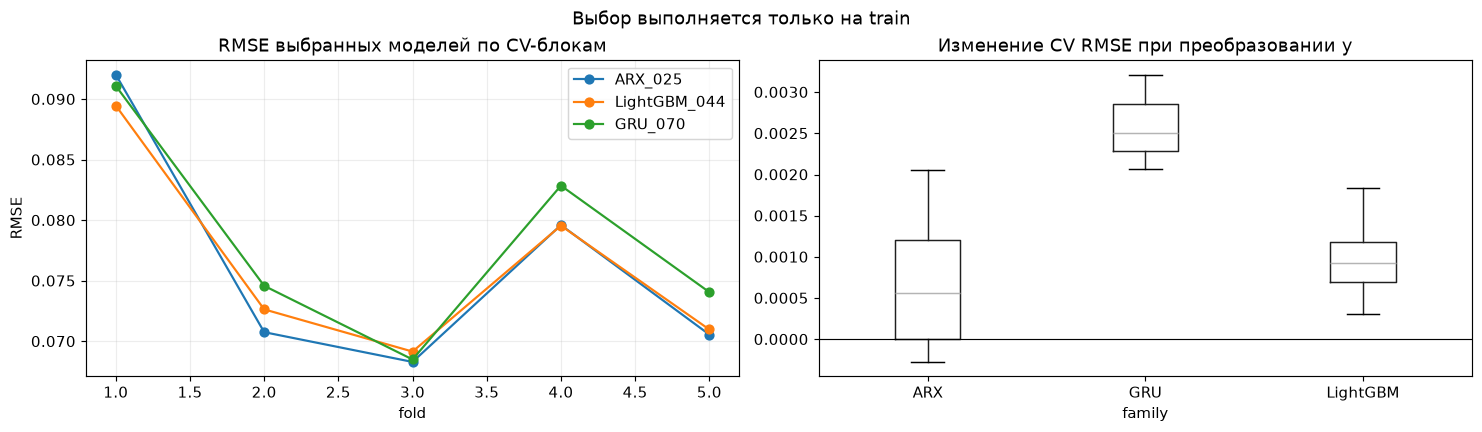

In [ ]:
EXP_DIR = Path('results/experiments')
exp_configs, exp_cv, exp_oof = experiment_search(
    Xtr, ytr, tele_tr, ACTIVE, LAB_CORE, gap_splits(ytr.index), EXP_DIR)
exp_winners = exp_cv.groupby('family', sort=False).head(1)
main_names = [exp_winners.index[exp_winners.family.eq(f)][0] for f in ['ARX', 'LightGBM', 'GRU']]
display(exp_cv)
display(exp_winners)
exp_folds = pd.DataFrame({name: exp_oof[name].groupby('fold').apply(
    lambda p: rmse(p.fact, p.pred), include_groups=False) for name in main_names}).T
display(exp_folds)
gru_name = main_names[2]
seed_scores = gru_seed_stability(exp_configs[gru_name], Xtr, ytr, tele_tr,
                                 list(gap_splits(ytr.index)), EXP_DIR)
seed_scores[42] = exp_cv.loc[gru_name, 'CV_RMSE']
display(pd.Series(seed_scores, name='GRU CV RMSE по seed').sort_index().to_frame())

paired_rows = []
for name, cfg in exp_configs.items():
    if cfg['target'] not in ('sqrt', 'boxcox', 'yeojohnson', 'standard'):
        continue
    baseline_target = 'standard' if cfg['family'] == 'GRU' else 'raw'
    if cfg['target'] == baseline_target:
        continue
    base_cfg = dict(cfg, target=baseline_target)
    matches = [key for key, val in exp_configs.items() if val == base_cfg]
    if matches:
        paired_rows.append({'model': name, 'family': cfg['family'], 'transform': cfg['target'],
            'baseline': matches[0], 'Δ CV RMSE': exp_cv.loc[name, 'CV_RMSE']-
                                                exp_cv.loc[matches[0], 'CV_RMSE']})
transform_pairs = pd.DataFrame(paired_rows)
display(transform_pairs.groupby(['family', 'transform'])['Δ CV RMSE'].agg(['mean', 'min', 'max']))
transform_pairs.to_csv(EXP_DIR / 'paired_transformations.csv', index=False)
exp_winners.to_csv(EXP_DIR / 'selected_configs.csv')
exp_folds.to_csv(EXP_DIR / 'selected_cv_folds.csv')
pd.Series(seed_scores).to_csv(EXP_DIR / 'gru_seed_stability.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
exp_folds.T.plot(marker='o', ax=axes[0]); axes[0].set(title='RMSE выбранных моделей по CV-блокам', ylabel='RMSE')
transform_pairs.boxplot(column='Δ CV RMSE', by='family', ax=axes[1], grid=False)
axes[1].axhline(0, color='k', lw=.8); axes[1].set_title('Изменение CV RMSE при преобразовании y')
fig.suptitle('Выбор выполняется только на train'); plt.show()


## 2.3. Оценка качества моделей

RMSE, MAE, MAPE и WAPE считаем в точках, где есть реальные пробы. Для MAPE берём только ненулевые фактические значения.

С направлением есть два сравнения. Сначала смотрим, совпадает ли знак изменения между соседними пробами, если факт изменился и между пробами прошло не больше шести часов. Если прогноз остался на месте, считаем это промахом. Потом смотрим, правильно ли модель оценивает, выше или ниже текущая концентрация относительно последней пробы, которую уже получил оператор. Также сравниваем разброс прогноза с фактом и считаем корреляцию последовательных изменений.

### 2.3.4. Точечные метрики и метрики направления

In [27]:
predictors, fit_sec, predictions = {}, {}, {}
for name in chosen_names:
    start = time.perf_counter()
    predictors[name] = fit_candidate(specs[name], Xtr, ytr)
    fit_sec[name] = time.perf_counter() - start
    predictions[name] = predictors[name](Xte)
pred_table = pd.DataFrame({'fact': yte, **predictions})
dy = np.diff(yte)
gaps = np.diff(yte.index) / np.timedelta64(1, 'm')
pairs = (gaps <= 360) & (dy != 0)
strong = pairs & (np.abs(dy) >= np.quantile(np.abs(np.diff(ytr)), .75))
known_level = Xte['lab__last'].to_numpy()
operator_delta = yte.to_numpy() - known_level
operator_pairs = np.isfinite(operator_delta) & (operator_delta != 0)

def test_metrics(pred):
    err = np.asarray(pred) - yte.to_numpy()
    dy_hat = np.diff(pred)
    nonzero = yte.ne(0)
    return {
        'MAE': np.abs(err).mean(), 'RMSE': rmse(yte, pred),
        'MAPE %': 100 * np.mean(np.abs(err[nonzero] / yte[nonzero])),
        'WAPE %': 100 * np.sum(np.abs(err)) / np.sum(np.abs(yte)),
        'R²': 1 - np.sum(err**2) / np.sum((yte - yte.mean())**2),
        'Bias': err.mean(), 'DA %': 100 * np.mean(np.sign(dy[pairs]) == np.sign(dy_hat[pairs])),
        'DA больших шагов %': 100 * np.mean(np.sign(dy[strong]) == np.sign(dy_hat[strong])),
        'DA к известной пробе %': 100 * np.mean(
            np.sign(operator_delta[operator_pairs]) == np.sign((pred - known_level)[operator_pairs])
        ),
        'corr Δ': np.corrcoef(dy[pairs], dy_hat[pairs])[0, 1] if dy_hat[pairs].std() > 0 else np.nan,
        'σ прогноза / σ факта': np.std(pred) / np.std(yte),
    }

metrics = pd.DataFrame({name: test_metrics(p) for name, p in predictions.items()}).T
print(f'Тест: {len(yte)} проб, {pairs.sum()} ненулевых переходов, из них крупных {strong.sum()}')
display(metrics.sort_values('RMSE'))

Тест: 318 проб, 299 ненулевых переходов, из них крупных 64


,MAE,RMSE,MAPE %,WAPE %,R²,Bias,DA %,DA больших шагов %,DA к известной пробе %,corr Δ,σ прогноза / σ факта
ols_arx,0.0519,0.0675,28.7584,24.7500,0.2934,0.0149,41.1371,42.1875,70.5298,-0.2453,0.6800
lgbm_arx_75_3_1,0.0533,0.0679,28.4139,25.3941,0.2870,0.0080,37.7926,28.1250,71.8543,-0.2793,0.6430
ridge_arx_2400_0.7,0.0514,0.0683,27.6181,24.5170,0.2774,0.0078,37.4582,32.8125,71.1921,-0.2790,0.7050
lab_ar,0.0547,0.0704,30.4407,26.0807,0.2331,0.0156,36.4548,29.6875,62.9139,-0.4020,0.5573
lab_smooth_ewm,0.0552,0.0715,28.5630,26.3066,0.2080,0.0005,32.4415,15.6250,67.8808,-0.5043,0.6029
ridge_slow_2400,0.0587,0.0779,29.5676,27.9892,0.0611,-0.0069,55.1839,59.3750,67.8808,0.1382,0.5668
last_lab,0.0595,0.0801,29.7174,28.3682,0.0074,0.0000,35.1171,29.6875,0.0000,-0.3864,0.9996
ridge_tele_2400,0.0696,0.0837,42.0383,33.1982,-0.0852,0.0373,59.1973,68.7500,65.2318,0.1897,0.3734
lgbm_tele_25_2,0.0739,0.0866,43.6996,35.2591,-0.1610,0.0333,41.4716,32.8125,61.2583,-0.0482,0.0871
train_mean,0.0804,0.0919,48.4705,38.3253,-0.3085,0.0446,0.0000,0.0000,60.5960,NaN,0.0000


In [28]:
exp_predictions, exp_predictors, exp_speed = fit_final_experiments(
    exp_configs, main_names, Xtr, ytr, Xte, tele_both, ACTIVE, LAB_CORE)
exp_metrics = pd.DataFrame({name: test_metrics(p) for name, p in exp_predictions.items()}).T
for name in main_names:
    predictions[name] = exp_predictions[name]
    pred_table[name] = exp_predictions[name]
metrics = pd.concat([metrics, exp_metrics])
display(metrics.loc[['last_lab', best_lab, 'ols_arx', best_hybrid, *main_names]])
display(exp_speed)
exp_metrics.to_csv(EXP_DIR / 'selected_test_metrics.csv')
pred_table[['fact', *main_names]].to_csv(EXP_DIR / 'selected_test_predictions.csv')
exp_speed.to_csv(EXP_DIR / 'selected_efficiency.csv')
print('Три основные модели выбраны по CV. Тестовый рейтинг не меняет выбор параметров.')


,MAE,RMSE,MAPE %,WAPE %,R²,Bias,DA %,DA больших шагов %,DA к известной пробе %,corr Δ,σ прогноза / σ факта
last_lab,0.0595,0.0801,29.7174,28.3682,0.0074,0.0000,35.1171,29.6875,0.0000,-0.3864,0.9996
lab_ar,0.0547,0.0704,30.4407,26.0807,0.2331,0.0156,36.4548,29.6875,62.9139,-0.4020,0.5573
ols_arx,0.0519,0.0675,28.7584,24.7500,0.2934,0.0149,41.1371,42.1875,70.5298,-0.2453,0.6800
lgbm_arx_75_3_1,0.0533,0.0679,28.4139,25.3941,0.2870,0.0080,37.7926,28.1250,71.8543,-0.2793,0.6430
ARX_025,0.0528,0.0675,29.7057,25.1974,0.2952,0.0166,42.1405,39.0625,69.2053,-0.2971,0.5737
LightGBM_044,0.0527,0.0674,27.8717,25.1465,0.2960,0.0063,40.1338,34.3750,70.8609,-0.2687,0.6426
GRU_070,0.0524,0.0694,26.9935,25.0008,0.2537,0.0004,37.1237,35.9375,70.8609,-0.2827,0.7420


,fit_s,predict_ms_per_1000
ARX_025,0.0061,6.5642
LightGBM_044,0.2562,12.0299
GRU_070,2.8872,431.6767


Три основные модели выбраны по CV. Тестовый рейтинг не меняет выбор параметров.


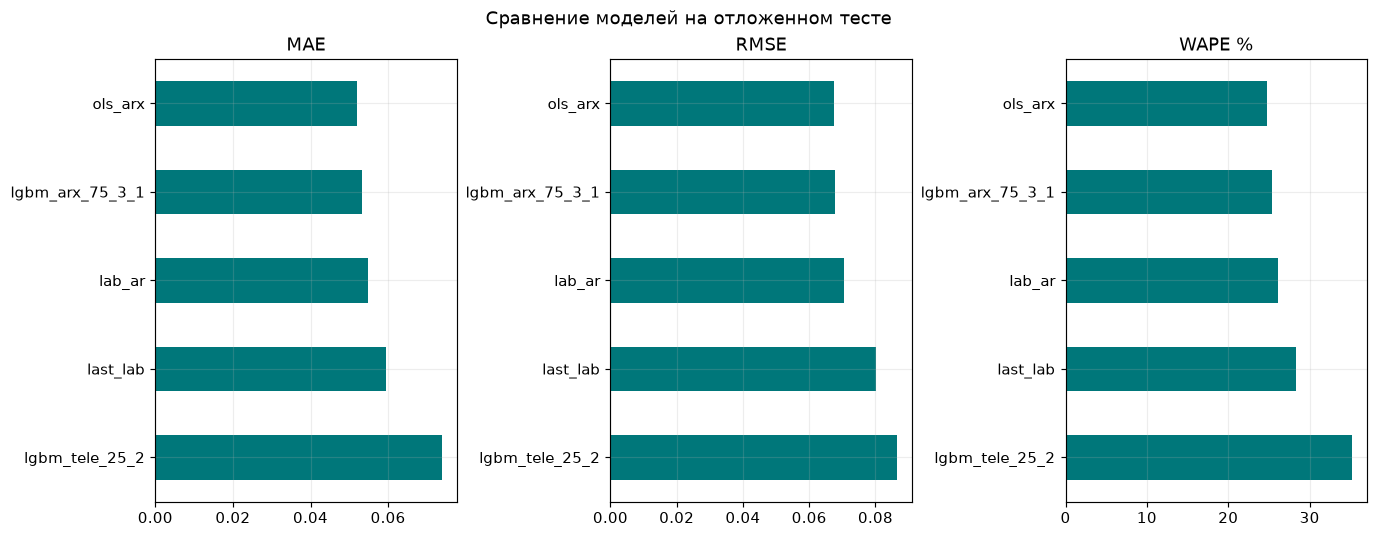

In [29]:

table = metrics.loc[['last_lab', best_lab, best_hybrid, 'ols_arx', best_tele]]
fig, axes = plt.subplots(1, 3, figsize=(13, 5), layout='constrained')
for ax, metric in zip(axes, ('MAE', 'RMSE', 'WAPE %')):
    table[metric].sort_values(ascending=False).plot.barh(ax=ax, color='#00777a')
    ax.set_title(metric)
fig.suptitle('Сравнение моделей на отложенном тесте')
plt.show()


### 2.3.5. Парные интервалы разности RMSE

In [30]:
def paired_rmse_interval(pred, base, block=12, n_resamples=3000):
    rng = np.random.default_rng(SEED)
    starts = rng.integers(0, len(yte) - block + 1,
                          size=(n_resamples, int(np.ceil(len(yte) / block))))
    take = (starts[..., None] + np.arange(block)).reshape(n_resamples, -1)[:, :len(yte)]
    err, ref_err = yte.to_numpy() - pred, yte.to_numpy() - base
    delta = np.sqrt((err[take]**2).mean(axis=1)) - np.sqrt((ref_err[take]**2).mean(axis=1))
    return np.quantile(delta, [.025, .975])

comparison = pd.DataFrame([
    {'модель': model, 'ориентир': ref, 'блок, проб': block,
     'Δ RMSE': metrics.loc[model, 'RMSE'] - metrics.loc[ref, 'RMSE'],
     **dict(zip(['95% нижняя', '95% верхняя'], paired_rmse_interval(predictions[model], predictions[ref], block)))}
    for model, ref in [(best_hybrid, 'last_lab'), (best_hybrid, best_lab),
                       (best_tele, 'last_lab'), (best_lab, 'last_lab')]
    for block in (6, 12, 24)
])
display(comparison)

,модель,ориентир,"блок, проб",Δ RMSE,95% нижняя,95% верхняя
0,lgbm_arx_75_3_1,last_lab,6,-0.0122,-0.0175,-0.0074
1,lgbm_arx_75_3_1,last_lab,12,-0.0122,-0.0169,-0.0076
2,lgbm_arx_75_3_1,last_lab,24,-0.0122,-0.0176,-0.0076
3,lgbm_arx_75_3_1,lab_ar,6,-0.0025,-0.0051,0.0002
4,lgbm_arx_75_3_1,lab_ar,12,-0.0025,-0.0048,-0.0000
5,lgbm_arx_75_3_1,lab_ar,24,-0.0025,-0.0047,-0.0001
6,lgbm_tele_25_2,last_lab,6,0.0065,-0.0038,0.0160
7,lgbm_tele_25_2,last_lab,12,0.0065,-0.0037,0.0167
8,lgbm_tele_25_2,last_lab,24,0.0065,-0.0053,0.0171
9,lab_ar,last_lab,6,-0.0097,-0.0136,-0.0060


### 2.3.6. Прогнозы и фактические измерения

На первом рисунке весь тест, а на втором три участка, где фактическая концентрация сильнее менялась. Для каждого участка берём по 18 часов до и после выбранного замера. Чёрные точки показывают лабораторные результаты. Прогнозы ARX, LightGBM и GRU показаны на тех же минутах. Линии просто соединяют точки, а оценки между пробами сохраняются отдельно в CSV.

На третьем рисунке чем ближе точка к диагонали, тем ближе прогноз к факту. В заголовках указан R² по всем тестовым пробам.

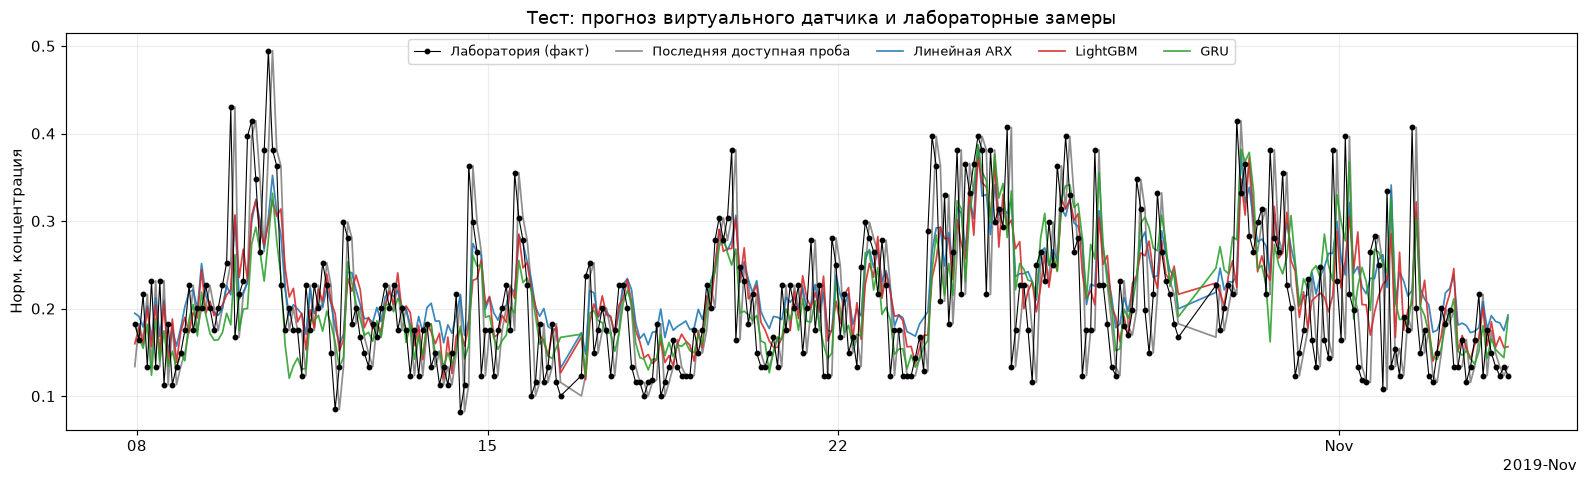

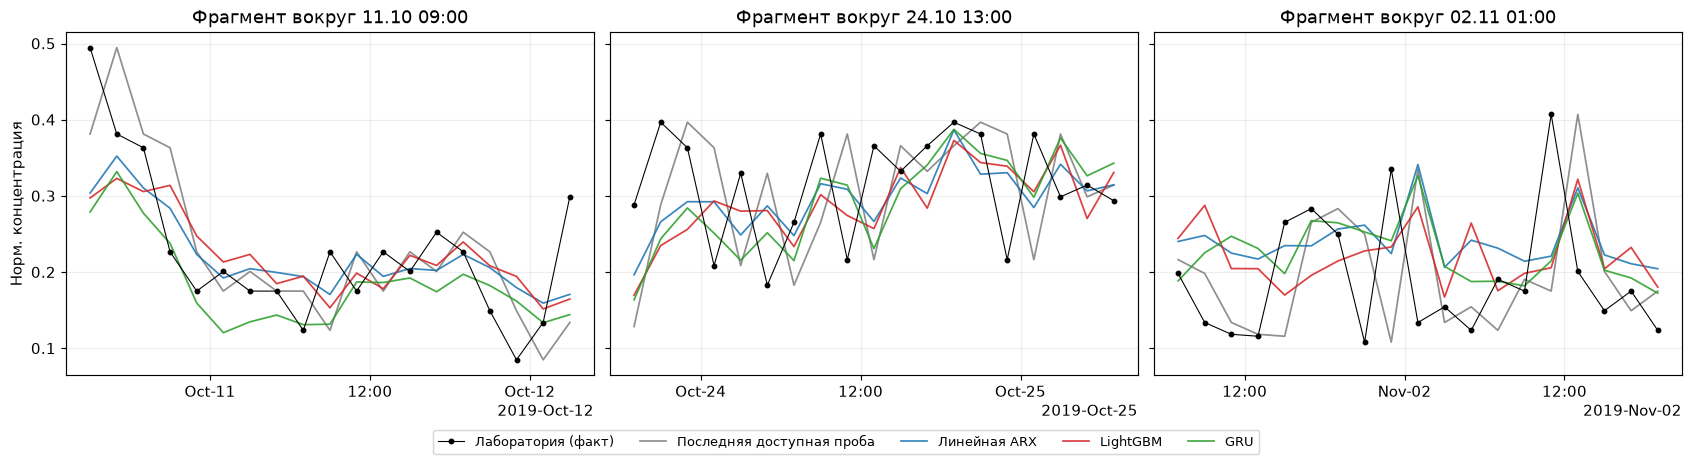

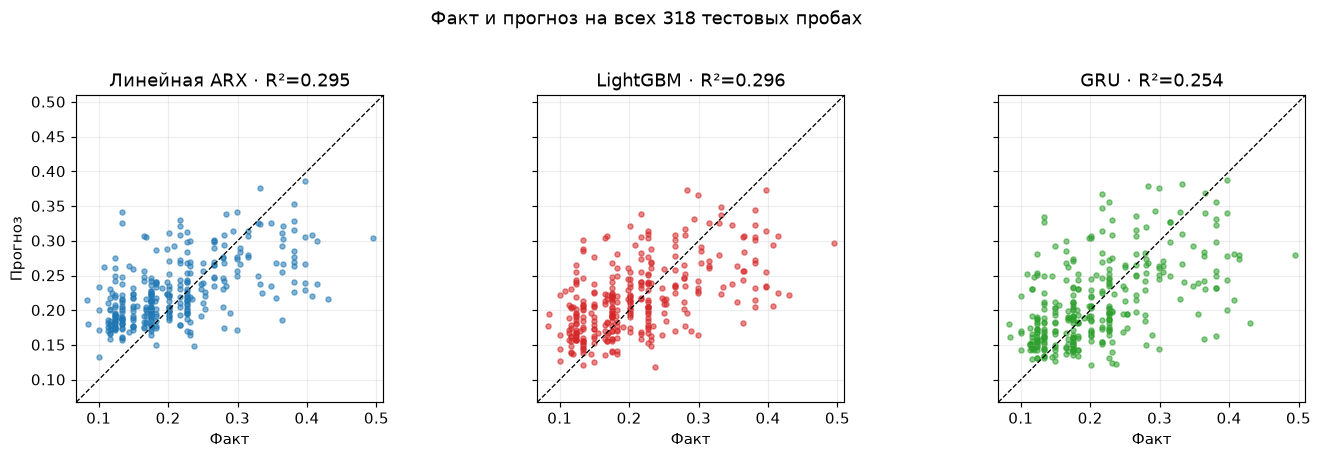

In [31]:
focus = ['last_lab', *main_names]
test_minutes = tele_grid_te.index
minute_inputs = inputs(tele_both, test_minutes, all_labs)
minute_pred = pd.DataFrame({'last_lab': predictors['last_lab'](minute_inputs),
    **{name: exp_predictors[name](minute_inputs) for name in main_names}}, index=test_minutes)
np.testing.assert_allclose(minute_pred.loc[yte.index, focus], pred_table[focus], rtol=1e-4, atol=1e-5)
colors = dict(zip(focus, ['gray', 'tab:blue', 'tab:red', 'tab:green']))
labels = dict(zip(focus, ['Последняя доступная проба', 'Линейная ARX', 'LightGBM', 'GRU']))

def plot_period(ax, frame, title):
    ax.plot(frame.index, frame['fact'], 'ko-', ms=3, lw=.75,
            label='Лаборатория (факт)', zorder=3)
    for name in focus:
        ax.plot(frame.index, frame[name], lw=1.2, alpha=.88,
                color=colors[name], label=labels[name])
    ax.set_title(title)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

fig, ax = plt.subplots(figsize=(15, 4.5), layout='constrained')
plot_period(ax, pred_table, 'Тест: прогноз виртуального датчика и лабораторные замеры')
ax.set_ylabel('Норм. концентрация')
ax.legend(ncol=5, loc='upper center', fontsize=9)
fig.savefig(OUT_DIR / 'predictions.png', dpi=160)
plt.show()

rolling_std = pred_table['fact'].rolling(15, min_periods=5).std().dropna()
centers = []
for stamp in rolling_std.sort_values(ascending=False).index:
    if all(abs(stamp - center) > pd.Timedelta(days=2) for center in centers):
        centers.append(stamp)
    if len(centers) == 3:
        break

width = pd.Timedelta(hours=18)
centers.sort()
fig, axes = plt.subplots(1, len(centers), figsize=(16, 4.3), sharey=True, layout='constrained')
for ax, center in zip(np.atleast_1d(axes), centers):
    window = pred_table.loc[center - width:center + width]
    plot_period(ax, window, f'Фрагмент вокруг {center:%d.%m %H:%M}')
np.atleast_1d(axes)[0].set_ylabel('Норм. концентрация')
handles, names = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, names, loc='outside lower center', ncol=5, fontsize=9)
fig.savefig(OUT_DIR / 'predictions_zoom.png', dpi=160)
plt.show()

models = focus[1:]
values = pred_table[['fact', *models]]
lo, hi = values.min().min() - .015, values.max().max() + .015
fig, axes = plt.subplots(1, len(models), figsize=(14, 4.5), sharex=True, sharey=True)
fig.subplots_adjust(left=.08, right=.98, top=.80, bottom=.15, wspace=.15)
fig.suptitle(f'Факт и прогноз на всех {len(pred_table)} тестовых пробах')
for ax, name in zip(np.atleast_1d(axes), models):
    ax.scatter(values['fact'], values[name], s=12, alpha=.55, color=colors[name])
    ax.plot([lo, hi], [lo, hi], 'k--', lw=.9)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect='equal', xlabel='Факт',
           title=f'{labels[name]} · R²={metrics.loc[name, "R²"]:.3f}')
np.atleast_1d(axes)[0].set_ylabel('Прогноз')
fig.savefig(OUT_DIR / 'fact_vs_prediction.png', dpi=160)
plt.show()

### 2.3.7. Остатки и обнаружение отклонений

Из фактического значения вычитаем прогноз. По тесту Бройша–Пагана смотрим, связан ли разброс остатков с прогнозом и давностью последней пробы. Для ACF и теста Льюнга–Бокса берём лаги по номеру пробы, так как интервалы между замерами разные.

Границы для проверки отклонений берём по 5-му и 95-му процентилям train. Они показывают, какие замеры редкие относительно обучающей выборки. Допустимые значения концентрации для печи в задании не указаны.

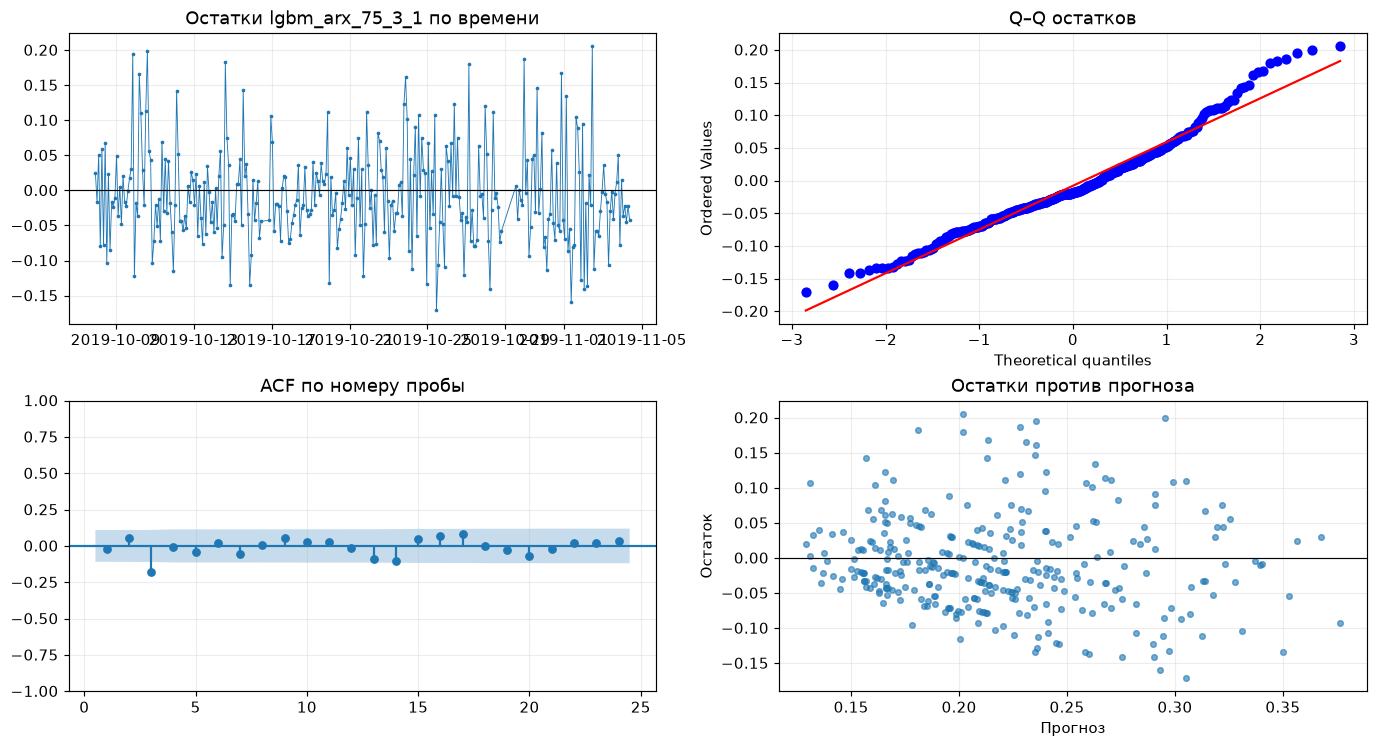

,Shapiro p,Ljung–Box p (12 проб),Breusch–Pagan p,ACF lag 1
lab_ar,0.0000,0.5448,0.0044,-0.1130
lgbm_tele_25_2,0.0000,0.0000,0.8791,0.4940
lgbm_arx_75_3_1,0.0000,0.2423,0.0002,-0.0216


In [32]:
diag = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout='constrained')
for name in (best_lab, best_tele, best_hybrid):
    e = yte.to_numpy() - predictions[name]
    exog = pd.DataFrame({'pred': predictions[name], 'age': Xte['lab__age_h'].to_numpy()}).fillna(0)
    diag[name] = {
        'Shapiro p': stats.shapiro(e).pvalue,
        'Ljung–Box p (12 проб)': acorr_ljungbox(e, lags=[12], return_df=True).lb_pvalue.iloc[0],
        'Breusch–Pagan p': het_breuschpagan(e, sm.add_constant(exog))[1],
        'ACF lag 1': pd.Series(e).autocorr(1),
    }
e = yte - predictions[best_hybrid]
axes[0, 0].plot(e.index, e, '.-', ms=3, lw=.6)
axes[0, 0].axhline(0, color='k', lw=.8)
axes[0, 0].set_title(f'Остатки {best_hybrid} по времени')
stats.probplot(e, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('Q–Q остатков')
plot_acf(e, ax=axes[1, 0], lags=24, zero=False)
axes[1, 0].set_title('ACF по номеру пробы')
axes[1, 1].scatter(predictions[best_hybrid], e, s=15, alpha=.6)
axes[1, 1].axhline(0, color='k', lw=.8)
axes[1, 1].set(xlabel='Прогноз', ylabel='Остаток', title='Остатки против прогноза')
fig.savefig(OUT_DIR / 'residuals.png', dpi=160)
plt.show()
display(pd.DataFrame(diag).T)

In [33]:
def excursion_metrics(p):
    low, high = ytr.quantile([.05, .95])
    truth = (yte < low) | (yte > high)
    alarm = (p < low) | (p > high)
    tp = int((truth & alarm).sum())
    precision = tp / alarm.sum() if alarm.any() else 0.0
    recall = tp / truth.sum() if truth.any() else 0.0
    return {'сигналов': int(alarm.sum()), 'истинных отклонений': int(truth.sum()),
            'precision': precision, 'recall': recall,
            'F1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0}

excursions = pd.DataFrame({name: excursion_metrics(p) for name, p in predictions.items()}).T
display(excursions)

,сигналов,истинных отклонений,precision,recall,F1
lab_ar,0.0000,29.0000,0.0000,0.0000,0.0000
lgbm_arx_75_3_1,0.0000,29.0000,0.0000,0.0000,0.0000
ols_arx,2.0000,29.0000,0.5000,0.0345,0.0645
ridge_arx_2400_0.7,1.0000,29.0000,0.0000,0.0000,0.0000
lab_smooth_ewm,0.0000,29.0000,0.0000,0.0000,0.0000
last_lab,29.0000,29.0000,0.3103,0.3103,0.3103
ridge_slow_2400,1.0000,29.0000,0.0000,0.0000,0.0000
lgbm_tele_25_2,0.0000,29.0000,0.0000,0.0000,0.0000
train_mean,0.0000,29.0000,0.0000,0.0000,0.0000
ridge_tele_2400,0.0000,29.0000,0.0000,0.0000,0.0000


### 2.3.8. Важность признаков и физическая интерпретация

Переставляем тестовые пробы блоками по 12 наблюдений. Все признаки одного датчика меняем вместе, поскольку у одного канала может быть много похожих лагов и окон. Смотрим, насколько после этого растёт RMSE. Для контрольного LightGBM SHAP показывает вклад в прогнозируемую поправку к лабораторному уровню, который прибавляется отдельно.

Названия датчиков засекречены, поэтому можно сравнить важность каналов по их номерам и посмотреть, какие лаги и окна выделяются.

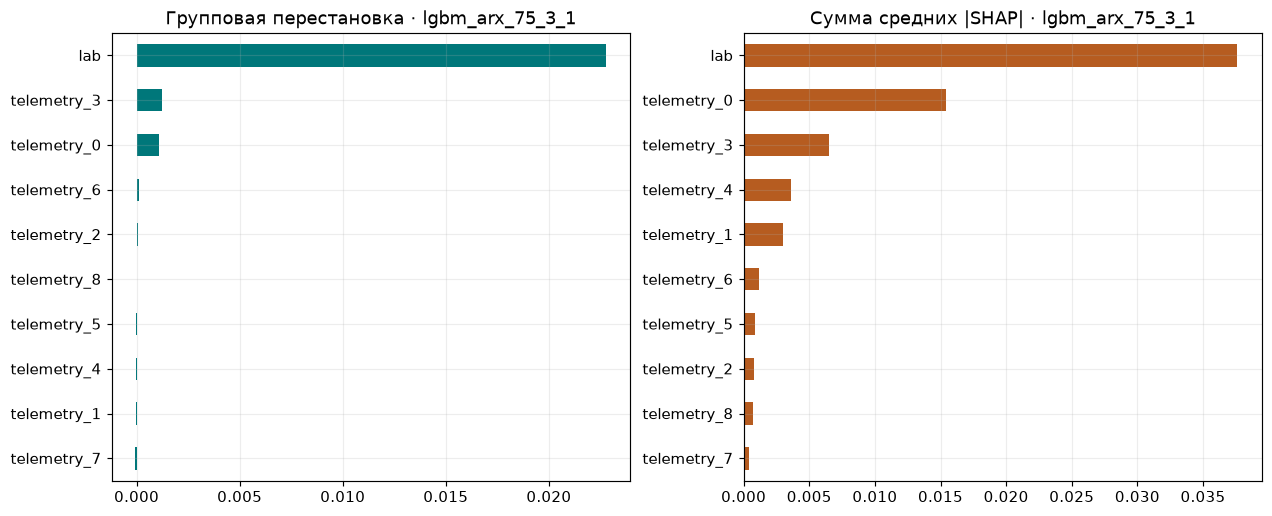

,среднее |SHAP|
lab__mean3,0.0160
lab__delta,0.0106
lab__previous,0.0054
telemetry_0__diff_since_lab,0.0044
telemetry_4__std60,0.0033
lab__mean5,0.0031
telemetry_0__raw,0.0017
telemetry_3__min120,0.0016
telemetry_0__min30,0.0015
telemetry_0__lag5,0.0013


In [34]:
def grouped_permutation(predict, X, y, repeats=12, block=12):
    rng = np.random.default_rng(SEED)
    blocks = [np.arange(i, min(i + block, len(X))) for i in range(0, len(X), block)]
    original_rmse = rmse(y, predict(X))
    result = {}
    for sensor in [*ACTIVE, 'lab']:
        cols = X.columns[X.columns.str.startswith(sensor + '__')]
        change = []
        for _ in range(repeats):
            mapping = np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])
            altered = X.copy()
            altered[cols] = X.iloc[mapping][cols].to_numpy()
            change.append(rmse(y, predict(altered)) - original_rmse)
        result[sensor] = (np.mean(change), np.std(change))
    return pd.DataFrame(result, index=['Δ RMSE', 'SD']).T.sort_values('Δ RMSE', ascending=False)

perm = grouped_permutation(predictors[best_hybrid], Xte, yte)
tree_name = chosen.index[chosen['family'].eq('lgbm_arx')][0]
tree_spec = specs[tree_name]
tree_columns, correction_weight = tree_spec[1], tree_spec[-1]
shap_values = shap.TreeExplainer(predictors[tree_name].model)(Xte[tree_columns])
importance = pd.Series(np.abs(shap_values.values).mean(axis=0) * correction_weight, index=tree_columns)
shap_grouped = importance.groupby(importance.index.str.split('__').str[0]).sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
perm.iloc[::-1]['Δ RMSE'].plot.barh(ax=axes[0], color='#00777a')
axes[0].set_title(f'Групповая перестановка · {best_hybrid}')
shap_grouped.iloc[::-1].plot.barh(ax=axes[1], color='#b65c20')
axes[1].set_title(f'Сумма средних |SHAP| · {tree_name}')
plt.show()
display(importance.sort_values(ascending=False).head(10).to_frame('среднее |SHAP|'))

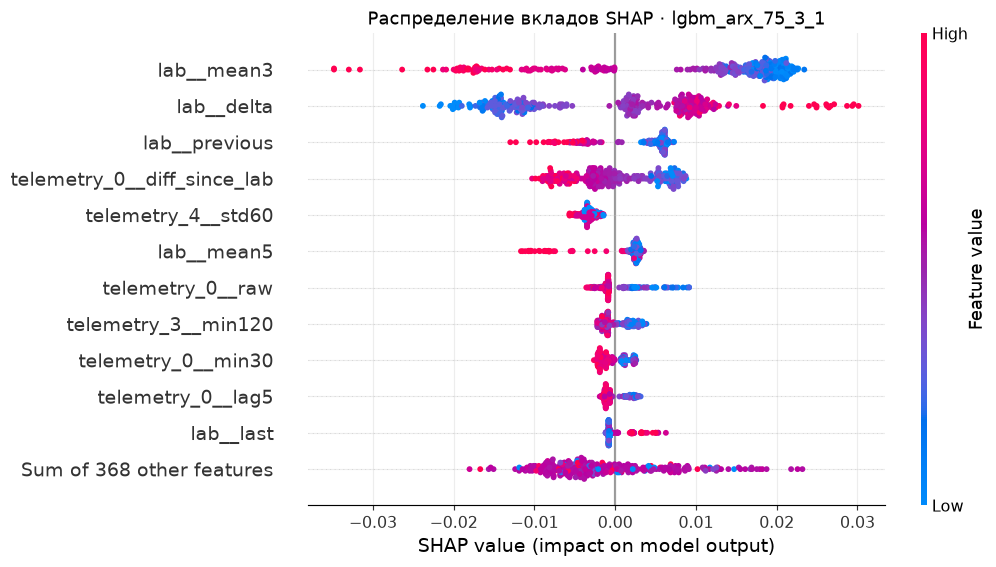

In [35]:

shap.plots.beeswarm(shap_values, max_display=12, show=False, plot_size=(10, 5.5))
plt.title(f'Распределение вкладов SHAP · {tree_name}')
plt.tight_layout()
plt.show()


### 2.3.9. AIC/BIC и вычислительная эффективность

In [36]:
# Явное гауссово правдоподобие: обе OLS-модели обучены на одинаковых строках.
ic = {}
for name, cols in [('lab_ar', LAB_CORE), ('ols_arx', FEATS_LINEAR)]:
    _, fit = fit_ols(Xtr, ytr, cols)
    ic[name] = {'n': int(fit.nobs), 'k': len(fit.params), 'AIC': fit.aic, 'BIC': fit.bic}
display(pd.DataFrame(ic).T)

speed = {}
for name, pred in predictors.items():
    start = time.perf_counter()
    for _ in range(15):
        pred(Xte)
    speed[name] = {'обучение, с': fit_sec[name],
                   'предсказание, мс / 1000': 1e6 * (time.perf_counter() - start) / (15 * len(Xte))}
display(pd.DataFrame(speed).T)
print('Замер скорости исключает загрузку, подготовку признаков и запись результата.')

,n,k,AIC,BIC
lab_ar,1772.0000,5.0000,-4063.8168,-4036.4175
ols_arx,1772.0000,23.0000,-4185.1047,-4059.0678


,"обучение, с","предсказание, мс / 1000"
lab_ar,0.0044,5.1362
lgbm_arx_75_3_1,0.2146,13.3308
ols_arx,0.0083,7.1091
ridge_arx_2400_0.7,0.0848,17.0253
lab_smooth_ewm,0.0001,0.1449
last_lab,0.0000,0.1238
ridge_slow_2400,0.0406,13.9822
lgbm_tele_25_2,0.0963,10.0770
train_mean,0.0001,0.0086
ridge_tele_2400,0.1061,15.2952


Замер скорости исключает загрузку, подготовку признаков и запись результата.


AIC и BIC считаем для двух моделей с коэффициентами OLS на одних и тех же пробах. У модели с телеметрией оба критерия ниже, но на временной валидации контрольная лабораторная AR показала меньший RMSE, чем OLS с телеметрией. Для остальных моделей сравниваем ошибки на валидации и время работы.

### Выводы по контрольным моделям

На 318 пробах у первой версии LightGBM с историей лаборатории получился RMSE 0,0679 против 0,0801 у последней доступной пробы. Выигрыш перед лабораторной AR гораздо меньше и составляет примерно 0,0025. При блочном бутстрепе с шестью пробами в блоке интервал для этой разницы включает ноль.

На графиках модель улавливает часть подъёмов и спадов, но сглаживает пики. Например, 10 октября в 15 часов фактическое значение было 0,4948, а прогноз около 0,2955. Направление между соседними пробами совпало в 37,8% случаев, а направление относительно последней известной пробы совпало в 71,9% случаев. Это два разных сравнения. Ridge только по телеметрии чаще угадывала направление соседних изменений (59,2%), но её RMSE выше и составляет 0,0837.

LightGBM пропустил все 29 точек за учебными границами. При перестановке сильнее всего повлияла история проб, а среди датчиков выделились каналы 3 и 0. На графике SHAP также заметен часовой разброс канала 4.

### 2.3.10. Диагностика трёх выбранных моделей

Сравним остатки у ARX, LightGBM и GRU, а также посмотрим, сколько тестовых значений за учебным диапазоном заметила каждая модель. Чтобы оценить разброс разницы RMSE, используем парный блочный бутстреп. Он сохраняет соседние пробы внутри блока.

Важность признаков смотрим через перестановку блоков на тесте. Для ARX и LightGBM переставляем все признаки одного канала вместе, а у GRU переставляем окно датчика вместе с маской пропусков. Лабораторную историю во всех случаях перемешиваем целиком. Так видно, насколько прогноз зависит от этих входов. Настройки моделей по этой проверке не меняем.

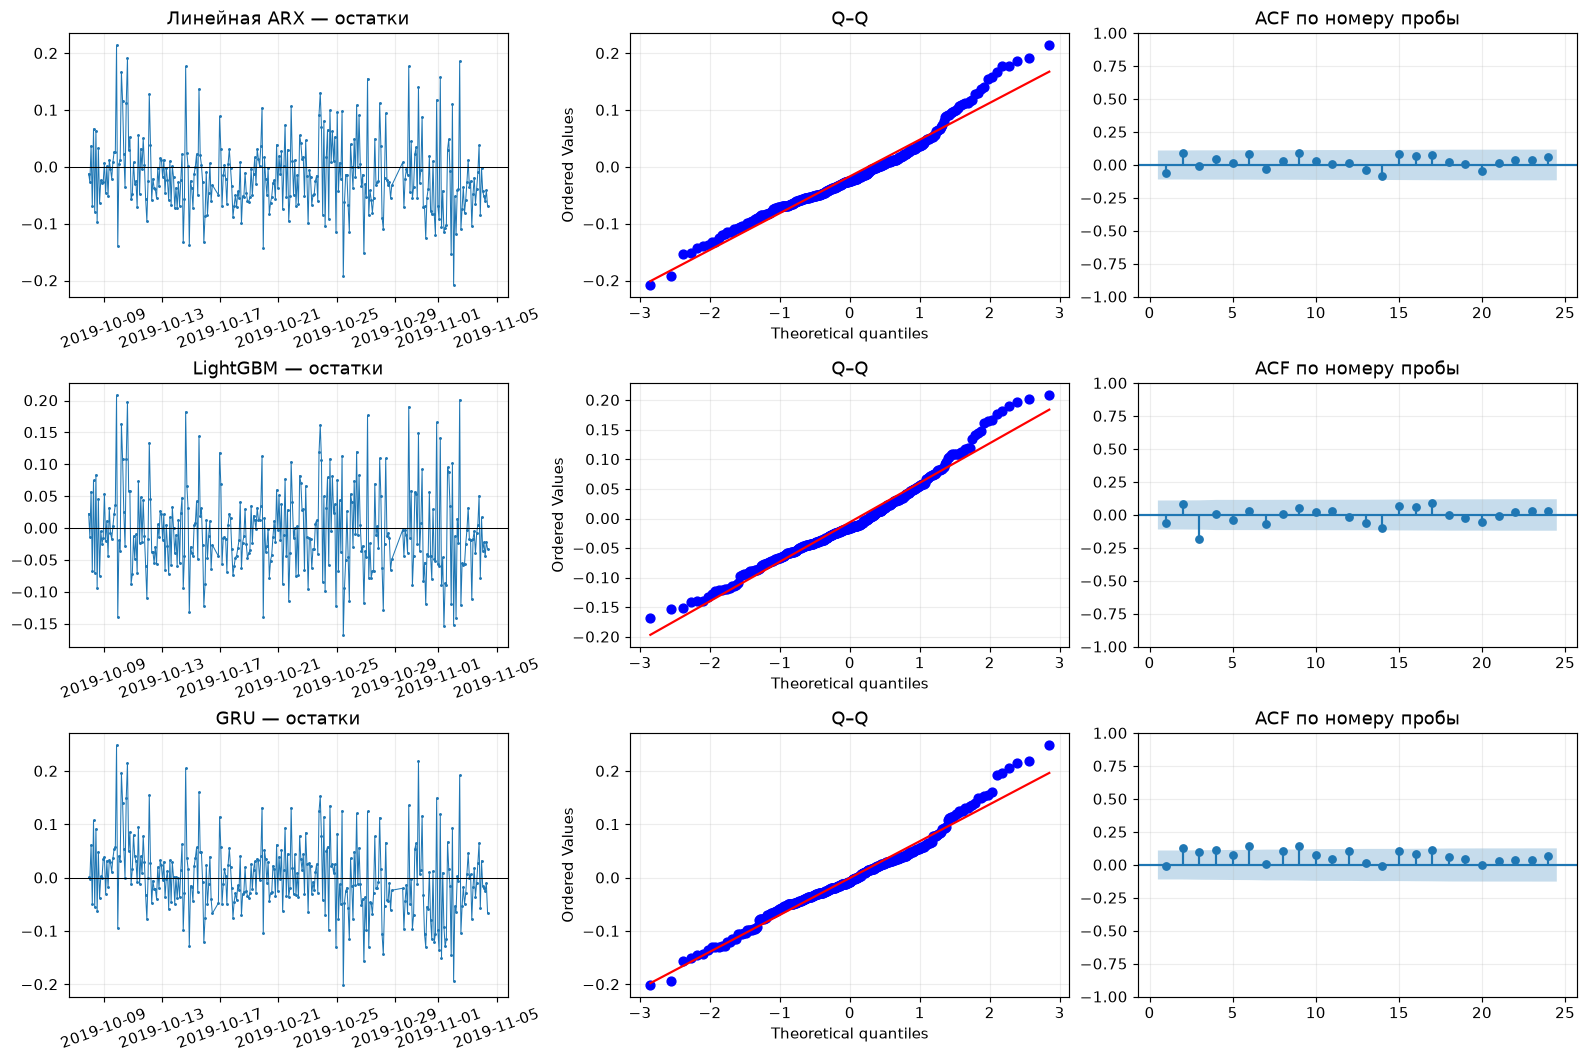

,Shapiro p,Ljung–Box p (12 проб),Breusch–Pagan p,сигналов,истинных отклонений,precision,recall,F1
ARX_025,0.0000,0.5844,0.0002,0.0000,29.0000,0.0000,0.0000,0.0000
LightGBM_044,0.0000,0.1315,0.0001,2.0000,29.0000,0.0000,0.0000,0.0000
GRU_070,0.0001,0.0002,0.0002,2.0000,29.0000,0.0000,0.0000,0.0000


,model,baseline,Δ RMSE,low,high
0,ARX_025,last_lab,-0.0126,-0.0174,-0.0081
1,ARX_025,lab_ar,-0.0029,-0.0053,-0.0008
2,LightGBM_044,last_lab,-0.0126,-0.0173,-0.0083
3,LightGBM_044,lab_ar,-0.0029,-0.0053,-0.0005
4,GRU_070,last_lab,-0.0106,-0.0156,-0.0057
5,GRU_070,lab_ar,-0.0009,-0.0051,0.0034


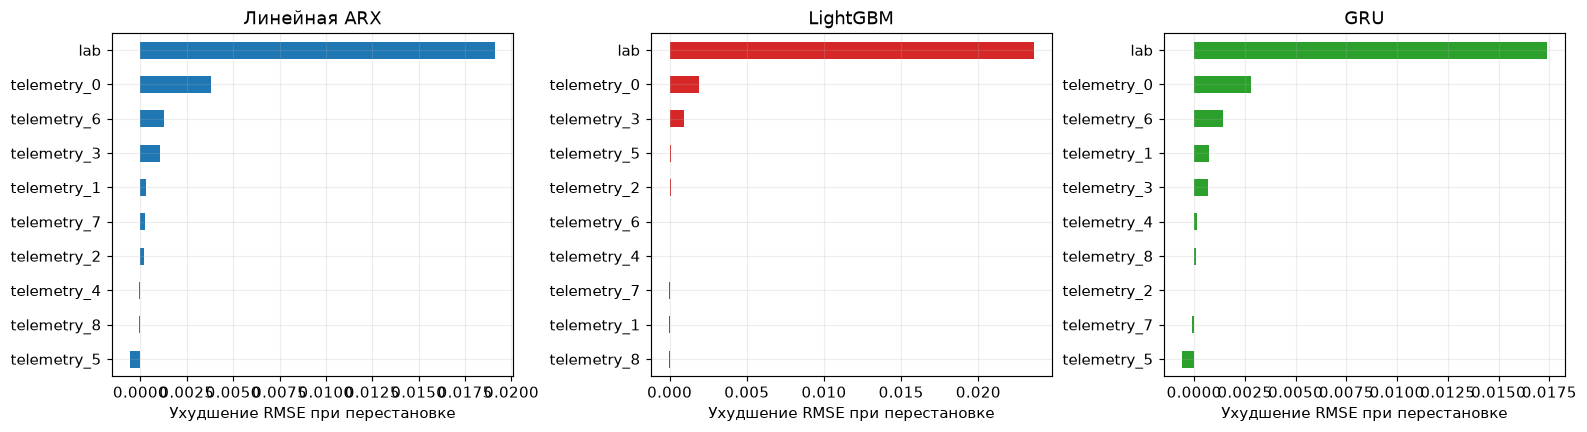

AIC/BIC выше относятся только к Gaussian OLS в исходной шкале на общих наблюдениях.
Они не используются для ранжирования Ridge, LightGBM и GRU или разных шкал таргета.
Время GRU включает построение последовательностей; число параметров: 833


In [37]:
exp_diag = {}
fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout='constrained')
for row, name in enumerate(main_names):
    p = exp_predictions[name]; e = yte.to_numpy() - p
    exp_diag[name] = {'Shapiro p': stats.shapiro(e).pvalue,
        'Ljung–Box p (12 проб)': acorr_ljungbox(e, lags=[12], return_df=True).lb_pvalue.iloc[0],
        'Breusch–Pagan p': het_breuschpagan(e, sm.add_constant(np.c_[p, Xte['lab__age_h'].fillna(0)]))[1],
        **excursion_metrics(p)}
    axes[row, 0].plot(yte.index, e, '.-', ms=2, lw=.7); axes[row, 0].axhline(0, c='k', lw=.7)
    axes[row, 0].set_title(f'{labels[name]} — остатки'); axes[row, 0].tick_params(axis='x', rotation=20)
    stats.probplot(e, plot=axes[row, 1]); axes[row, 1].set_title('Q–Q')
    plot_acf(e, lags=24, zero=False, ax=axes[row, 2]); axes[row, 2].set_title('ACF по номеру пробы')
plt.show()
display(pd.DataFrame(exp_diag).T)
exp_bootstrap = pd.DataFrame([{'model': name, 'baseline': base,
    'Δ RMSE': rmse(yte, exp_predictions[name])-rmse(yte, predictions[base]),
    **dict(zip(['low', 'high'], paired_rmse_interval(exp_predictions[name], predictions[base])))}
    for name in main_names for base in ['last_lab', best_lab]])
display(exp_bootstrap)

exp_importance = {}
for name in main_names[:2]:
    exp_importance[name] = grouped_permutation(exp_predictors[name], Xte, yte, repeats=6)
gmodel = exp_predictors[gru_name].model
gseq = sequence_windows(tele_both, Xte.index, exp_configs[gru_name]['window'])
gcols = list(Xtr.filter(like='lab__').columns)
blocks = [np.arange(i, min(i+12, len(yte))) for i in range(0, len(yte), 12)]
rng = np.random.default_rng(SEED)
gimp = {}
for j, sensor in enumerate([*ACTIVE, 'lab']):
    differences = []
    for repeat in range(6):
        order = np.concatenate([blocks[k] for k in rng.permutation(len(blocks))])
        altered = gseq.copy(); context = Xte[gcols].copy()
        if sensor == 'lab':
            context.iloc[:] = context.iloc[order].to_numpy()
        else:
            altered[:, :, j] = gseq[order, :, j]
        q = gmodel.predict(altered, context)
        differences.append(rmse(yte, q) - rmse(yte, exp_predictions[gru_name]))
    gimp[sensor] = (np.mean(differences), np.std(differences))
exp_importance[gru_name] = pd.DataFrame(gimp, index=['Δ RMSE', 'SD']).T.sort_values('Δ RMSE', ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
for ax, name in zip(axes, main_names):
    exp_importance[name]['Δ RMSE'].sort_values().plot.barh(ax=ax, color=colors[name])
    ax.set_title(labels[name]); ax.set_xlabel('Ухудшение RMSE при перестановке')
plt.show()
pd.DataFrame(exp_diag).T.to_csv(EXP_DIR / 'selected_residuals_excursions.csv')
exp_bootstrap.to_csv(EXP_DIR / 'selected_bootstrap.csv', index=False)
pd.concat(exp_importance).to_csv(EXP_DIR / 'selected_permutation.csv')
print('AIC/BIC выше относятся только к Gaussian OLS в исходной шкале на общих наблюдениях.')
print('Они не используются для ранжирования Ridge, LightGBM и GRU или разных шкал таргета.')
print('Время GRU включает построение последовательностей; число параметров:',
      sum(p.numel() for p in gmodel.net.parameters()))


## 2.4. Документирование и итоговые выводы

На тесте все три модели оказались лучше прогноза по последней доступной пробе. По RMSE LightGBM и ARX практически одинаковые, а у GRU немного ниже MAE. На валидации лабораторная AR всё же лучше каждой из трёх моделей. Поэтому по этой выборке видно улучшение относительно последней пробы, а выигрыш именно от телеметрии зависит от периода.

| Модель | CV RMSE | Test RMSE | MAE | WAPE, % | R² | DA, % |
|---|---|---|---|---|---|---|
| ARX | 0,0768 | 0,0675 | 0,0528 | 25,20 | 0,295 | 42,1 |
| LightGBM | 0,0767 | 0,0674 | 0,0527 | 25,15 | 0,296 | 40,1 |
| GRU | 0,0786 | 0,0694 | 0,0524 | 25,00 | 0,254 | 37,1 |
| Последняя доступная проба | 0,0847 | 0,0801 | 0,0595 | 28,37 | 0,007 | 35,1 |
| Только лабораторная AR | 0,0759 | 0,0704 | 0,0547 | 26,08 | 0,233 | 36,5 |

### Преобразования и параметры

У ARX оставляем StandardScaler для признаков и Ridge с α = 300. Из телеметрии берём средние и разности за час. Исходный и стандартизированный таргет дали практически одинаковый результат.

LightGBM лучше отработал с исходной шкалой признаков и таргета. В выбранном варианте 150 деревьев глубины 2 и минимум 45 наблюдений в листе. Модель предсказывает поправку к среднему трёх доступных проб.

У GRU получилось лучше со стандартизацией входов и таргета. Берём окно 60 минут, то есть 12 пятиминутных шагов, и 8 скрытых состояний. Учим 20 эпох с AdamW и шагом 0,003. GRU тоже предсказывает поправку к среднему трёх доступных проб. При трёх значениях seed RMSE на валидации был от 0,0780 до 0,0789.

Квадратный корень, Box–Cox и Yeo–Johnson не попали ни в одну из трёх выбранных конфигураций. При одинаковых остальных настройках они помогли в 2 из 18 сравнений у ARX, а у LightGBM и GRU не помогли ни в одном из 18 и 3 сравнений соответственно. У GRU это проверяли при 40 эпохах, так что вывод относится к этим настройкам. Нормализация каждого окна также оказалась хуже общей стандартизации. Возможно, причина в том, что она убирает различия в уровне датчиков между окнами.

### Что видно по прогнозам и остаткам

По графикам видно, что модели улавливают часть общих подъёмов и спадов, но сглаживают резкие пики. Разброс прогнозов составляет примерно 57% от фактического у ARX, 64% у LightGBM и 74% у GRU. У ARX заметнее среднее завышение (+0,0166), у LightGBM оно меньше (+0,0063), а у GRU близко к нулю (+0,0004). Направление соседних изменений совпадает примерно в 37–42% случаев.

У 29 тестовых проб фактическое значение было ниже 5-го или выше 95-го процентиля train. Ни одна из трёх моделей не дала прогноз за теми же границами в момент этих проб. Это учебные пороги по распределению концентрации.

По тестам у всех трёх моделей остатки отличаются от нормального распределения и их разброс меняется. У GRU тест Льюнга–Бокса показал зависимость по времени (p около 0,00015). Для ARX и LightGBM тест по 12 лагам её не выявил (p около 0,58 и 0,13).

Наибольшее ухудшение RMSE при перестановке даёт история лаборатории. Среди каналов у всех трёх моделей выделяется `telemetry_0`. Дальше у ARX и GRU идёт `telemetry_6`, а у LightGBM `telemetry_3`. По этим номерам можно сказать, что каналы важны для прогноза, но их физический смысл по данным определить нельзя.

### Что можно проверить на этих данных

Я бы отдельно сравнил ошибки на больших и малых изменениях концентрации. Общий RMSE показывает, что оценка уровня стала лучше относительно последней пробы, а по редким пикам всё ещё много промахов. В следующем эксперименте можно попробовать повысить вес крайних значений при обучении и проверить по временным блокам, заметит ли модель больше таких точек и насколько вырастет число ложных срабатываний.

### Контрольные результаты предыдущей версии

В исходном варианте LightGBM и LSTM давали почти постоянный прогноз. После постоянной поправки уровня RMSE у LightGBM составил 0,0785 против 0,0801 у последней пробы, но MAE и WAPE оказались выше. Поправка меняет уровень линии, поэтому совпадение направления между соседними точками от неё не меняется.

### Общий вывод 
Честно, не знаю хороший ли это результат. Я честно попробовал использовать различные преобразования с лекций, чтобы улучшить проноз, они особо не дали каких-то результатов, возможно, я что-то упускаю, но не могу понять, что именно. Помогли улучшить прогноз результаты предыдущих проб, но модели все равно не могут реагировать хорошо на резкие скачки. Если вы дочитаете до этого момента, то не могли бы объяснить, как улучшить прогнозы конкретно этого ряда, потому что у меня уже нет идей, что можно с ним сделать. 

### Сохранение артефактов

In [38]:
metrics.to_csv(OUT_DIR / 'metrics_test.csv')
selection.to_csv(OUT_DIR / 'metrics_cv.csv')
pred_table.to_csv(OUT_DIR / 'predictions_at_samples.csv')
minute_pred.to_csv(OUT_DIR / 'predictions_minute.csv')
comparison.to_csv(OUT_DIR / 'paired_bootstrap.csv', index=False)
excursions.to_csv(OUT_DIR / 'excursions_test.csv')
pd.DataFrame(diag).T.to_csv(OUT_DIR / 'residual_tests.csv')
perm.to_csv(OUT_DIR / 'permutation_groups.csv')
importance.sort_values(ascending=False).to_csv(OUT_DIR / 'shap.csv')
pd.DataFrame(ic).T.to_csv(OUT_DIR / 'information_criteria.csv')
pd.DataFrame(speed).T.to_csv(OUT_DIR / 'efficiency.csv')
print(f'Прогнозов на минутной сетке: {len(minute_pred):,}. Лабораторных точек для проверки: {len(yte)}.')

Прогнозов на минутной сетке: 39,747. Лабораторных точек для проверки: 318.
